# BVOC emissions: background change versus forest expansion (FUT), after the CO₂ fix

New-chain version of `bvoc_emissions_decomposition.ipynb` (kept as the old-chain record: CTRL `-20260925`, LCC `-20261005`, `_IM` fBVOC, 2001–2009). Runs used here, **2001–2014** (year 2000 dropped as spin-up):

| Alias | Case (CO₂-fix chain) |
|---|---|
| CTRL_PD | `NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029` |
| LCC_PD | `NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028` |
| CTRL_FUT | `NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028` |
| LCC_FUT | `NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028` |
| LCC_FUT_fBVOCctrlPD | `NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19_f19-20261031` |
| LCC_FUT_fBVOCctrlFUT | `NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOCctrlFUT_f19_f19-20261031` |
| LCC_FUT_fBVOClccPD | `NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOClccPD_f19_f19-20261031` |
| CTRL_FUT_fBVOCctrlFUT | `NF2100ssp585norbc_tropstratchem_nudg_ctrl_fBVOCctrlFUT_f19_f19-20261031` |

**Figure style (project):** line/bar colours from the project palette (teal, navy, plum, red, orange, gold; gold = total/sum; PD navy, FUT red). Maps: continuous `RdBu_r`, symmetric scale; **hatched = not significant** (paired yearly t-test, Benjamini–Hochberg FDR α = 0.10 over the cells ≥45°N, as in `plotting/forcing_maps.py`); dark outline = modified cells.

Single notebook for **CTRL_PD, CTRL_FUT and LCC_FUT**, 2001–2014, monthly SFISOP/SFMTERP. It merges and replaces the earlier `bvoc_emissions_decomposition`, `bvoc_emissions_three_regions` and `bvoc_emissions_followup_investigation` notebooks.

**Background = CTRL_FUT − CTRL_PD**  
**Expansion = LCC_FUT − CTRL_FUT**  
**Total = LCC_FUT − CTRL_PD = Background + Expansion**

This is an exact emissions decomposition, not a decomposition of cloud/radiative responses. Values are mass of the emitted compound, not carbon mass.

| Region | Question |
|---|---|
| Modified cells within ≥45°N | What happens within the imposed vegetation-change footprint? |
| Unmodified cells ≥45°N | What happens outside that footprint? |
| All cells ≥45°N | What is the combined northern budget? |

For an exact partition, **modified cells are intersected with the northern domain**. Any modified cells south of the threshold are counted and reported, but excluded. The first two regions are disjoint; their emission totals sum to the third.

The expansion contrast includes vegetation-induced environmental responses, even within modified cells. It does not isolate a direct PFT emission-capacity effect. Background includes all environmental differences between the controls.

Sections 1–9 are the baseline decomposition; section 10 holds the conclusions drawn from it; sections 11–17 are the follow-up diagnostics (hotspots, mechanisms, fixed-emission checks, atmospheric responses). Sections 16–17 use the fBVOC runs listed above.

The PD-vs-FUT dependence of the expansion effect is in the separate notebook `bvoc_expansion_PD_FUT_interaction-after-co2-fix.ipynb`.

In [1]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
import os
os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")  # parallel reads on NIRD
from pathlib import Path
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from glob import glob
import calendar
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from IPython.display import display

A = "/cluster/home/adelez/BRL-FRST-XPSN_archive"
CASES = {  # new chain (CO2-fix spin-ups); every run covers 2000-2014
    "CTRL_PD": "NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029",
    "LCC_PD": "NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028",
    "CTRL_FUT": "NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028",
    "LCC_FUT": "NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028",
    "LCC_FUT_fBVOCctrlPD": "NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19_f19-20261031",
    "LCC_FUT_fBVOCctrlFUT": "NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOCctrlFUT_f19_f19-20261031",
    "LCC_FUT_fBVOClccPD": "NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOClccPD_f19_f19-20261031",
    "CTRL_FUT_fBVOCctrlFUT": "NF2100ssp585norbc_tropstratchem_nudg_ctrl_fBVOCctrlFUT_f19_f19-20261031",
}
CAM = {alias: f"{A}/{case}/atm/hist/*.cam.h0.*.nc" for alias, case in CASES.items()}
CLM = {alias: f"{A}/{case}/lnd/hist/*.clm2.h0.*.nc" for alias, case in CASES.items()}
FILES = {alias: CAM[alias] for alias in ("CTRL_PD", "CTRL_FUT", "LCC_FUT")}
START_YEAR, END_YEAR = 2001, 2014  # year 2000 = spin-up, dropped
MIN_LAT = 45
VARS = ["SFISOP", "SFMTERP"]
LABELS = {"SFISOP": "Isoprene", "SFMTERP": "Monoterpenes"}
TEAL, NAVY, PLUM, RED, ORANGE, GOLD = "#5D9A92", "#2C3990", "#9A4A84", "#BC423E", "#DE7A3A", "#EBC45C"
LIGHT_GREY = "#CCCCCC"  # residual / other
COLORS = {"Background": NAVY, "Expansion": TEAL, "Total": GOLD}
REGION_COLORS = {"Modified": RED, "Unmodified": NAVY, "All north": GOLD}  # All north = sum -> gold
OUT = Path("bvoc_emissions_decomposition-after-co2-fix_outputs")
OUT.mkdir(exist_ok=True)

# Set True only for processed files whose timestamps identify the represented month.
# Raw CAM next-month timestamps require time bounds.
TRUST_TIMESTAMPS_WITHOUT_BOUNDS = False
AREA_FILE = None  # Optional NetCDF with cell area on the same lat/lon grid.
AREA_VAR, AREA_UNITS = "area", "m2"  # Alternatives: km2, sr
EARTH_RADIUS = 6_371_000
MASK_FILE = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-modified-cells/modified_cells.nc")
MASK_VAR = None  # e.g. "modified_cells"; auto-detect only a unique binary 2D candidate.
MASK_NAN_IS_FALSE = False  # Set True only if missing values explicitly mean unmodified.

RUN_MAPS = True  # Cartopy maps (needs the lcc-env kernel with coastline data).
MAP_QUANTILE = 0.98  # map colour limit = this quantile of |change| >= MIN_LAT (extremes saturate)

# Speed-up (user OK 2026-11-07): raw h0 files are read 8 at a time in worker processes (threads would
# serialise on the netCDF/HDF5 lock), and each (run, variable) is read from disk only once (cache next to load_monthly_dataset).
N_READERS = 8
_POOL_CTX = mp.get_context("fork")  # workers inherit the functions and settings defined in this notebook


def parallel_map(func, items):
    with ProcessPoolExecutor(N_READERS, mp_context=_POOL_CTX) as pool:
        return list(pool.map(func, items))


## 0. Map style helpers
Copied from `plotting/forcing_maps.py` so the notebook stays self-contained.

In [2]:
# Map style copied from plotting/forcing_maps.py (this notebook is self-contained):
# continuous RdBu_r with a symmetric scale; NON-significant cells hatched with thin grey /////
# (paired yearly t-test, Benjamini-Hochberg FDR over the cells >= MIN_LAT, alpha 0.10, Wilks 2016);
# dark outline = modified cells. All runs are nudged to the same winds, so year y pairs with year y.
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import TwoSlopeNorm
from matplotlib.path import Path as MplPath
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from scipy import stats as sps

MAP_CMAP = "RdBu_r"
FDR_ALPHA = 0.10
CIRCLE = MplPath(np.column_stack([np.sin(np.linspace(0, 2 * np.pi, 200)),
                                  np.cos(np.linspace(0, 2 * np.pi, 200))]) * .5 + .5)
HATCH_NOTE = (f"hatched: not significant (paired yearly t-test, FDR α = {FDR_ALPHA:g} over cells ≥{MIN_LAT}°N); "
              "outline: modified cells")


def yearly_mean(field, months=None):
    """Duration-weighted yearly means (year, ..., lat, lon) of a monthly field; months e.g. [6, 7, 8]."""
    sec = seconds if months is None else seconds.where(reference.month.isin(months))
    return (field * sec).groupby("year").sum("time") / sec.groupby("year").sum("time")


def nonsignificant(yearly, within):
    """True where the yearly differences are NOT FDR-significant (only cells inside `within`)."""
    with np.errstate(invalid="ignore", divide="ignore"):
        p = sps.ttest_1samp(yearly.transpose("year", "lat", "lon").values, 0.0, axis=0,
                            nan_policy="omit").pvalue
    p = np.asarray(p)
    valid = np.isfinite(p) & within.values
    sig = np.zeros(p.shape, bool)
    ranked = np.sort(p[valid])
    below = np.nonzero(ranked <= FDR_ALPHA * np.arange(1, ranked.size + 1) / max(ranked.size, 1))[0]
    if below.size:
        sig = valid & (p <= ranked[below[-1]])
    return xr.DataArray(valid & ~sig, dims=("lat", "lon"), coords={"lat": yearly.lat, "lon": yearly.lon})


def symmetric_ticks(limit):
    """5-9 round, symmetric ticks inside +-limit (more than 5 when they fit)."""
    ticks = MaxNLocator(nbins=8, symmetric=True, steps=[1, 2, 2.5, 5, 10]).tick_values(-limit, limit)
    return ticks[np.abs(ticks) <= limit * (1 + 1e-9)]


def draw_map(ax, field, limit, nonsig=None, title=""):
    field = field.transpose("lat", "lon")
    cyclic, lon_c = add_cyclic_point(field.values, coord=field.lon.values)
    mesh = ax.pcolormesh(lon_c, field.lat, cyclic, transform=ccrs.PlateCarree(), cmap=MAP_CMAP,
                         norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit), shading="auto")
    if nonsig is not None and bool(nonsig.any()):
        data, lon_h = add_cyclic_point(nonsig.astype(float).values, coord=nonsig.lon.values)
        cs = ax.contourf(lon_h, nonsig.lat, np.where(data > .5, 1., np.nan), levels=[.5, 1.5],
                         colors="none", hatches=["/////"], transform=ccrs.PlateCarree(), zorder=4)
        cs.set_edgecolor("dimgrey")
        cs.set_linewidth(0.0)
        cs.set_hatch_linewidth(0.3)
    outline, lon_o = add_cyclic_point(modified.transpose("lat", "lon").values.astype(float),
                                      coord=modified.lon.values)
    ax.contour(lon_o, modified.lat, outline, levels=[.5], colors=["0.15"], linewidths=.5,
               transform=ccrs.PlateCarree(), zorder=5)
    ax.set_extent([-180, 180, MIN_LAT, 90], crs=ccrs.PlateCarree())
    ax.set_boundary(CIRCLE, transform=ax.transAxes)
    ax.coastlines(linewidth=.6, zorder=6)
    ax.set_title(title, fontsize=10)
    return mesh


def add_cbar(fig, axes, mesh, limit, label):
    cb = fig.colorbar(mesh, ax=axes, orientation="horizontal", shrink=.8, pad=.04, extend="both")
    cb.set_ticks(symmetric_ticks(limit))
    cb.ax.xaxis.set_major_formatter(FormatStrFormatter("%.3g"))
    cb.set_label(label)
    return cb

## 1. Read monthly emissions once
Uses time bounds to identify complete calendar months and retains only SFISOP/SFMTERP. Re-running later plotting cells does not reload simulation files.

In [3]:
def seconds_between(start, end):
    delta = end - start
    return float(delta / np.timedelta64(1, "s")) if isinstance(delta, np.timedelta64) else delta.total_seconds()

def date_parts(value):
    if isinstance(value, np.datetime64):
        value = pd.Timestamp(value)
    return value.year, value.month, value.day, value.hour, value.minute, value.second

def _read_case_file(path):
    """One raw h0 file -> (chunk of the selected months or None, month keys). Same checks as before."""
    with xr.open_dataset(path) as ds:
        bounds_name = ds.time.attrs.get("bounds")
        if not bounds_name or bounds_name not in ds:
            bounds_name = next((v for v in ("time_bnds", "time_bounds") if v in ds), None)
        selected, keys, durations = [], [], []
        for i, stamp in enumerate(ds.time.values):
            if bounds_name:
                start, end = ds[bounds_name].isel(time=i).values.ravel()
                midpoint = start + (end - start) / 2
                year, month, *_ = date_parts(midpoint)
                duration = seconds_between(start, end)
                sy, sm, sd, sh, smin, ss = date_parts(start)
                ey, em, ed, eh, emin, es = date_parts(end)
                next_month = (sy + (sm == 12), sm % 12 + 1)
                monthly = (sd == ed == 1 and (ey, em) == next_month
                           and (sy, sm) == (year, month) and 27 <= duration / 86400 <= 31
                           and sh == smin == ss == eh == emin == es == 0)
            else:
                if not TRUST_TIMESTAMPS_WITHOUT_BOUNDS:
                    raise ValueError(f"{path}: no time bounds; confirm timestamp convention in configuration.")
                year, month, *_ = date_parts(stamp)
                duration = float(ds.time.dt.days_in_month.isel(time=i)) * 86400
                monthly = True
            if not START_YEAR <= year <= END_YEAR:
                continue
            if not monthly:
                raise ValueError(f"{path}: record {i} is not a complete calendar month.")
            selected.append(i)
            keys.append(year * 100 + month)
            durations.append(duration)
        if not selected:
            return None, []
        for var in VARS:
            if set(ds[var].dims) != {"time", "lat", "lon"}:
                raise ValueError(f"{path}: unexpected dimensions for {var}: {ds[var].dims}")
            unit = ds[var].attrs.get("units", "").lower().replace(" ", "").replace("**", "^")
            if unit not in {"kg/m2/s", "kg/m^2/s", "kgm-2s-1", "kgm^-2s^-1"}:
                raise ValueError(f"{path}: verify units for {var}: {ds[var].attrs.get('units')}")
        chunk = ds[VARS].isel(time=selected).assign_coords(time=keys).load()
        chunk["seconds"] = ("time", durations)
        return chunk, keys


def read_case(pattern):
    paths = sorted(glob(str(Path(pattern).expanduser())))
    if not paths:
        raise FileNotFoundError(pattern)
    chunks, records = [], []
    for chunk, keys in parallel_map(_read_case_file, paths):
        if chunk is not None:
            chunks.append(chunk)
            records.extend(keys)
    expected = [y * 100 + m for y in range(START_YEAR, END_YEAR + 1) for m in range(1, 13)]
    if sorted(records) != expected:
        raise ValueError("Expected exactly one record per month; check gaps, duplicates and selected years.")
    result = xr.concat(chunks, dim="time", join="exact").sortby("time").sortby("lat").sortby("lon")
    result = result.assign_coords(year=("time", result.time.values // 100),
                                  month=("time", result.time.values % 100))
    if not bool(np.isfinite(result[VARS].to_array()).all()):
        raise ValueError("Missing/nonfinite emissions: inspect before spatial integration.")
    print(f"{len(paths)} files inspected; {result.sizes['time']} monthly records loaded.")
    return result

cases = {alias: read_case(pattern) for alias, pattern in FILES.items()}
cases = dict(zip(cases, xr.align(*cases.values(), join="exact")))
reference = cases["CTRL_PD"]
for alias, ds in cases.items():
    np.testing.assert_allclose(ds.seconds, reference.seconds, rtol=0, atol=0)

180 files inspected; 168 monthly records loaded.
180 files inspected; 168 monthly records loaded.
180 files inspected; 168 monthly records loaded.


## 2. Cell area
Fluxes are grid-box-area fluxes in kg m⁻² s⁻¹. Integrate over whole grid-cell area; do not multiply by land fraction or changed-PFT fraction again. A modified grid cell may contain both changed and unchanged vegetation.

The default area estimate applies only to a regular global latitude–longitude grid. A supplied model area field is preferable when available.

In [4]:
def grid_area(ds):
    lat, lon = ds.lat.values, ds.lon.values
    if len(lat) < 2 or len(lon) < 2:
        raise ValueError("Need a full grid or an explicit area file.")
    dlat, dlon = np.diff(lat), np.diff(lon)
    if not (np.allclose(dlat, dlat[0]) and np.allclose(dlon, dlon[0])):
        raise ValueError("Nonuniform grid: provide AREA_FILE.")
    if not np.isclose(dlon[0] * len(lon), 360):
        raise ValueError("Expected global longitude coverage; provide AREA_FILE.")
    if lat[0] - dlat[0] / 2 > -89.99 or lat[-1] + dlat[0] / 2 < 89.99:
        raise ValueError("Expected global latitude coverage; provide AREA_FILE.")
    edges = np.r_[-90, (lat[:-1] + lat[1:]) / 2, 90]
    bands = EARTH_RADIUS**2 * np.diff(np.sin(np.deg2rad(edges))) * np.deg2rad(dlon[0])
    return xr.DataArray(np.broadcast_to(bands[:, None], (len(lat), len(lon))),
                        dims=("lat", "lon"), coords={"lat": ds.lat, "lon": ds.lon})

if AREA_FILE:
    with xr.open_dataset(Path(AREA_FILE).expanduser()) as ds:
        area = ds[AREA_VAR].load().squeeze(drop=True).sortby("lat").sortby("lon")
    area = area * {"m2": 1, "km2": 1e6, "sr": EARTH_RADIUS**2}[AREA_UNITS]
    area, _ = xr.align(area, reference.SFISOP.isel(time=0, drop=True), join="exact")
else:
    area = grid_area(reference)
if set(area.dims) != {"lat", "lon"} or not bool((np.isfinite(area) & (area > 0)).all()):
    raise ValueError("Area must be finite, positive and two-dimensional.")



## 3. Inspect the mask and define the three regions
Only binary 0/1 masks are accepted. Extra singleton dimensions are removed, but time-dependent or PFT-dependent masks are not silently collapsed.

Longitude conventions are normalized before matching. Cell coordinates must then match the CAM grid within 0.00001°; no interpolation or nearest-neighbour remapping is performed. Missing mask values require an explicit choice.

In [5]:
with xr.open_dataset(MASK_FILE) as mask_ds:
    display(pd.DataFrame([{"variable": name, "dimensions": str(v.dims), "shape": str(v.shape),
                           "description": v.attrs.get("long_name", "")}
                          for name, v in mask_ds.data_vars.items()]))

    candidates = []
    for name, v in mask_ds.data_vars.items():
        v = v.squeeze(drop=True)
        if set(v.dims) == {"lat", "lon"}:
            vals = np.asarray(v.values)
            finite = vals[np.isfinite(vals)]
            if finite.size and np.isin(finite, [0, 1]).all():
                candidates.append(name)

    if MASK_VAR is None:
        if len(candidates) != 1:
            raise ValueError(f"Set MASK_VAR explicitly. Binary lat/lon candidates: {candidates}")
        selected_mask = candidates[0]
    else:
        selected_mask = MASK_VAR
    raw_mask = mask_ds[selected_mask].squeeze(drop=True).load()

if set(raw_mask.dims) != {"lat", "lon"}:
    raise ValueError(f"Expected a 2D lat/lon mask, got {raw_mask.dims}. Select the intended mask explicitly.")
raw_mask = raw_mask.transpose("lat", "lon")
raw_mask = raw_mask.assign_coords(lon=raw_mask.lon % 360).sortby("lon").sortby("lat")
target_lon = np.mod(reference.lon.values, 360)
order = np.argsort(target_lon)
if raw_mask.shape != (reference.sizes["lat"], reference.sizes["lon"]):
    raise ValueError("Mask and CAM grid sizes differ; use a mask on the CAM grid.")
np.testing.assert_allclose(raw_mask.lat.values, reference.lat.values, rtol=0, atol=1e-5,
                           err_msg="Mask latitude grid does not match CAM.")
np.testing.assert_allclose(raw_mask.lon.values, target_lon[order], rtol=0, atol=1e-5,
                           err_msg="Mask longitude grid does not match CAM.")

values = raw_mask.values[:, np.argsort(order)]
if np.isinf(values).any():
    raise ValueError("Infinite mask values are invalid.")
if np.isnan(values).any():
    if not MASK_NAN_IS_FALSE:
        raise ValueError("Mask has missing values. Inspect them; set MASK_NAN_IS_FALSE only if they mean unmodified.")
    values = np.nan_to_num(values, nan=0)
if not np.isin(values, [0, 1]).all():
    raise ValueError("Mask must contain only 0/1 values, not PFT fractions or category IDs.")

modified = xr.DataArray(values.astype(bool), dims=("lat", "lon"),
                        coords={"lat": reference.lat, "lon": reference.lon})
north = xr.ones_like(modified, dtype=bool) & (modified.lat >= MIN_LAT)
REGIONS = ["Modified", "Unmodified", "All north"]
region_masks = xr.concat([modified & north, ~modified & north, north],
                          pd.Index(REGIONS, name="region"))
region_weights = region_masks * area
region_area = region_weights.sum(("lat", "lon"))
if bool((region_area <= 0).any()):
    raise ValueError("At least one region is empty. Inspect the mask and latitude threshold.")

outside_count = int((modified & ~north).sum())
print(f"Mask variable: {selected_mask}")
print(f"Modified cells south of {MIN_LAT}°N excluded from this partition: {outside_count}")
region_table = pd.DataFrame({
    "cells": region_masks.sum(("lat", "lon")).values,
    "area_km2": region_area.values / 1e6,
    "percent_of_northern_area": region_area.values / float(region_area.sel(region="All north")) * 100,
}, index=REGIONS)
display(region_table.round(2))
region_table.to_csv(OUT / "region_areas.csv")
xr.testing.assert_equal(region_masks.sel(region="Modified", drop=True) |
                        region_masks.sel(region="Unmodified", drop=True), north)
assert not bool((region_masks.sel(region="Modified", drop=True) &
                 region_masks.sel(region="Unmodified", drop=True)).any())


,variable,dimensions,shape,description
0,modified,"('lat', 'lon')","(96, 144)",
1,max_pft_change_pp,"('lat', 'lon')","(96, 144)",


Mask variable: modified
Modified cells south of 45°N excluded from this partition: 0


,cells,area_km2,percent_of_northern_area
Modified,1161,29131097.73,39.79
Unmodified,2295,44081401.98,60.21
All north,3456,73212499.71,100.00


## 4. Calculate budgets and check both decompositions
Annual totals: Tg of emitted compound yr⁻¹. Flux means: mg m⁻² d⁻¹ over each region's whole area, including any ocean fraction. Annual means of monthly fluxes use month-duration weights.

Two checks: **Background + Expansion = Total**, and **Modified + Unmodified = All north** for integrated totals. Regional mean fluxes are not additive; they combine using region areas.

In [6]:
seconds = reference.seconds
fields = {alias: ds[VARS] for alias, ds in cases.items()}
delta = {"Background": fields["CTRL_FUT"] - fields["CTRL_PD"],
         "Expansion": fields["LCC_FUT"] - fields["CTRL_FUT"],
         "Total": fields["LCC_FUT"] - fields["CTRL_PD"]}
COMPARISONS = list(delta)
all_fields = {**fields, **delta}
flux = xr.concat(list(all_fields.values()), pd.Index(list(all_fields), name="comparison"))
monthly_mass = (flux * region_weights).sum(("lat", "lon"), skipna=False) * seconds / 1e9
annual = monthly_mass.groupby("year").sum("time")
regional_flux = (flux * region_weights).sum(("lat", "lon"), skipna=False) / region_area * 86400 * 1e6
mean_flux = (regional_flux * seconds).sum("time") / seconds.sum()
seasonal = (regional_flux * seconds).groupby("month").sum("time") / seconds.groupby("month").sum("time")

xr.testing.assert_allclose(annual.sel(comparison="Background", drop=True) +
                           annual.sel(comparison="Expansion", drop=True),
                           annual.sel(comparison="Total", drop=True))
xr.testing.assert_allclose(annual.sel(region="Modified", drop=True) +
                           annual.sel(region="Unmodified", drop=True),
                           annual.sel(region="All north", drop=True))
xr.testing.assert_allclose(
    (mean_flux.sel(region=["Modified", "Unmodified"]) *
     region_area.sel(region=["Modified", "Unmodified"])).sum("region") /
    region_area.sel(region="All north", drop=True),
    mean_flux.sel(region="All north", drop=True))
print("Emissions and regional budget closure checks passed.")

rows = []
for region in REGIONS:
    for comparison in all_fields:
        for var in VARS:
            years = annual[var].sel(region=region, comparison=comparison)
            rows.append({"region": region, "comparison": comparison, "species": LABELS[var],
                         "mean_Tg_per_year": float(years.mean("year")),
                         "interannual_SD_Tg_per_year": float(years.std("year", ddof=1)),
                         "mean_flux_mg_m2_day": float(mean_flux[var].sel(region=region, comparison=comparison))})
summary = pd.DataFrame(rows).set_index(["region", "comparison", "species"])
for region in REGIONS:
    print(region)
    display(summary.loc[region].round(4))
summary.to_csv(OUT / "emissions_summary_three_regions.csv")
annual.to_dataframe().to_csv(OUT / "annual_emissions_three_regions.csv")
seasonal.to_dataframe().to_csv(OUT / "seasonal_mean_flux_three_regions.csv")


Emissions and regional budget closure checks passed.
Modified


mean_Tg_per_year  interannual_SD_Tg_per_year  \
comparison species                                                      
CTRL_PD    Isoprene                4.1259                      0.3043   
           Monoterpenes            4.9761                      0.1933   
CTRL_FUT   Isoprene               12.4903                      0.8190   
           Monoterpenes           22.6006                      0.9012   
LCC_FUT    Isoprene               12.8522                      0.8459   
           Monoterpenes           22.4816                      0.8580   
Background Isoprene                8.3644                      0.5498   
           Monoterpenes           17.6246                      0.7256   
Expansion  Isoprene                0.3619                      0.1255   
           Monoterpenes           -0.1191                      0.1693   
Total      Isoprene                8.7263                      0.5721   
           Monoterpenes           17.5055                      0.6853   

                         mean_flux_mg_m2_day  
comparison species                            
CTRL_PD    Isoprene                   0.3880  
           Monoterpenes               0.4680  
CTRL_FUT   Isoprene                   1.1747  
           Monoterpenes               2.1255  
LCC_FUT    Isoprene                   1.2087  
           Monoterpenes               2.1143  
Background Isoprene                   0.7867  
           Monoterpenes               1.6576  
Expansion  Isoprene                   0.0340  
           Monoterpenes              -0.0112  
Total      Isoprene                   0.8207  
           Monoterpenes               1.6464

Unmodified


mean_Tg_per_year  interannual_SD_Tg_per_year  \
comparison species                                                      
CTRL_PD    Isoprene                5.2321                      0.3381   
           Monoterpenes            3.3648                      0.1414   
CTRL_FUT   Isoprene               10.7326                      0.6952   
           Monoterpenes           12.6101                      0.5761   
LCC_FUT    Isoprene               10.7581                      0.6535   
           Monoterpenes           12.6362                      0.5402   
Background Isoprene                5.5004                      0.3947   
           Monoterpenes            9.2453                      0.4469   
Expansion  Isoprene                0.0255                      0.0659   
           Monoterpenes            0.0261                      0.0562   
Total      Isoprene                5.5259                      0.3510   
           Monoterpenes            9.2714                      0.4108   

                         mean_flux_mg_m2_day  
comparison species                            
CTRL_PD    Isoprene                   0.3252  
           Monoterpenes               0.2091  
CTRL_FUT   Isoprene                   0.6670  
           Monoterpenes               0.7837  
LCC_FUT    Isoprene                   0.6686  
           Monoterpenes               0.7854  
Background Isoprene                   0.3419  
           Monoterpenes               0.5746  
Expansion  Isoprene                   0.0016  
           Monoterpenes               0.0016  
Total      Isoprene                   0.3434  
           Monoterpenes               0.5762

All north


mean_Tg_per_year  interannual_SD_Tg_per_year  \
comparison species                                                      
CTRL_PD    Isoprene                9.3581                      0.5485   
           Monoterpenes            8.3408                      0.3026   
CTRL_FUT   Isoprene               23.2229                      1.2734   
           Monoterpenes           35.2107                      1.2979   
LCC_FUT    Isoprene               23.6102                      1.2629   
           Monoterpenes           35.1178                      1.1851   
Background Isoprene               13.8648                      0.7806   
           Monoterpenes           26.8699                      1.0227   
Expansion  Isoprene                0.3874                      0.1694   
           Monoterpenes           -0.0930                      0.2170   
Total      Isoprene               14.2522                      0.7604   
           Monoterpenes           26.7769                      0.9077   

                         mean_flux_mg_m2_day  
comparison species                            
CTRL_PD    Isoprene                   0.3502  
           Monoterpenes               0.3121  
CTRL_FUT   Isoprene                   0.8690  
           Monoterpenes               1.3176  
LCC_FUT    Isoprene                   0.8835  
           Monoterpenes               1.3142  
Background Isoprene                   0.5188  
           Monoterpenes               1.0055  
Expansion  Isoprene                   0.0145  
           Monoterpenes              -0.0035  
Total      Isoprene                   0.5333  
           Monoterpenes               1.0020

## 5. Locate the negative expansion contribution
Signed Tg yr⁻¹ values are directly comparable and additive across the two component regions. Error bars are interannual standard deviations, not confidence intervals.

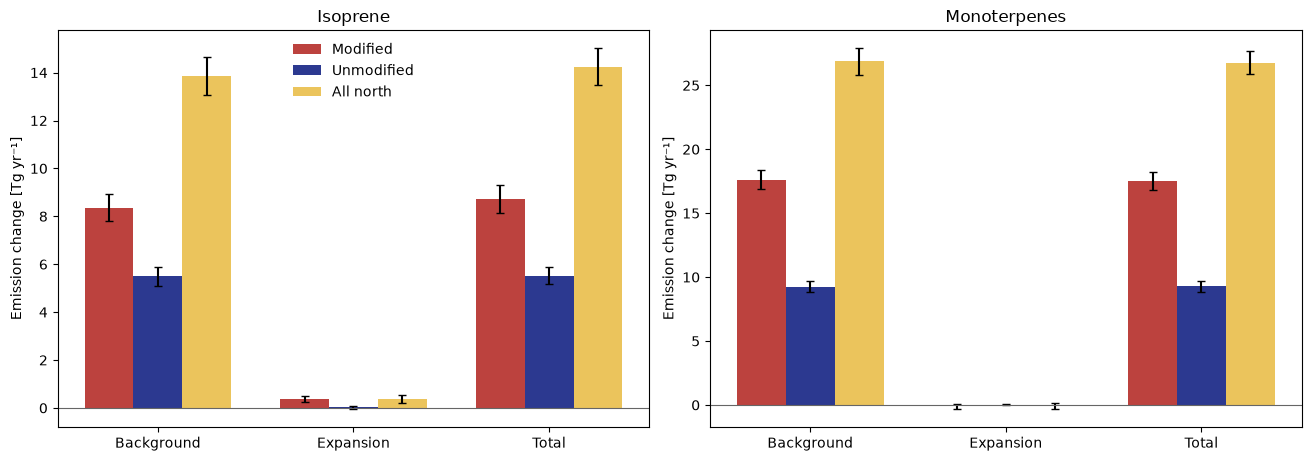

Isoprene expansion: modified +0.3619, unmodified +0.0255, all north +0.3874 Tg yr⁻¹
Monoterpenes expansion: modified -0.1191, unmodified +0.0261, all north -0.0930 Tg yr⁻¹


In [7]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
x, width = np.arange(len(COMPARISONS)), 0.25
region_colors = REGION_COLORS
for ax, var in zip(axes, VARS):
    for i, region in enumerate(REGIONS):
        y = annual[var].sel(region=region, comparison=COMPARISONS)
        ax.bar(x + (i - 1) * width, y.mean("year"), width,
               yerr=y.std("year", ddof=1), capsize=3, label=region, color=region_colors[region])
    ax.axhline(0, color="0.4", linewidth=0.8)
    ax.set(title=LABELS[var], xticks=x, xticklabels=COMPARISONS, ylabel="Emission change [Tg yr⁻¹]")
axes[0].legend(frameon=False)
fig.savefig(OUT / "regional_budget_contributions.png", dpi=200)
plt.show()

for var in VARS:
    parts = annual[var].sel(comparison="Expansion").mean("year")
    m, u, total = [float(parts.sel(region=r)) for r in REGIONS]
    print(f"{LABELS[var]} expansion: modified {m:+.4f}, unmodified {u:+.4f}, all north {total:+.4f} Tg yr⁻¹")

## 6. Annual consistency
Look for persistent signs and whether the northern signal is dominated by modified cells or by the larger surrounding area. Simulation years are time-slice sampling years, not a transient future trajectory.

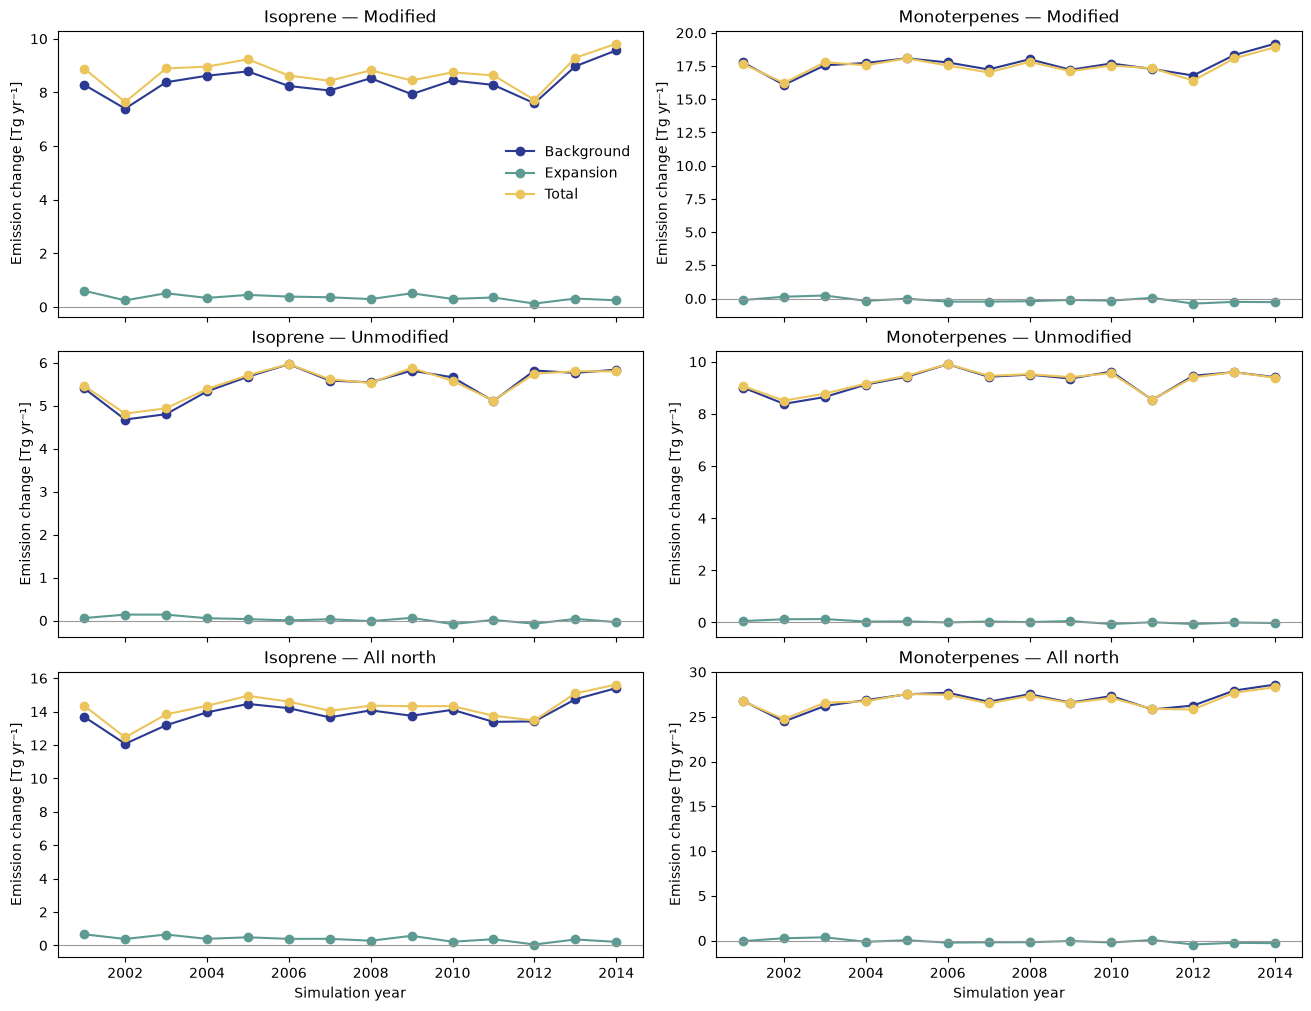

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        for name in COMPARISONS:
            values = annual[var].sel(region=region, comparison=name)
            ax.plot(values.year, values, "o-", color=COLORS[name], label=name)
        ax.axhline(0, color="0.6", linewidth=0.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Emission change [Tg yr⁻¹]")
        if i == 2:
            ax.set_xlabel("Simulation year")
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "annual_changes_three_regions.png", dpi=200)
plt.show()


## 7. Seasonal mean fluxes
Each mean uses its own region's area denominator. A stronger modified-cell mean does not necessarily imply a larger regional total. The y-scale is shared across regions for each species.

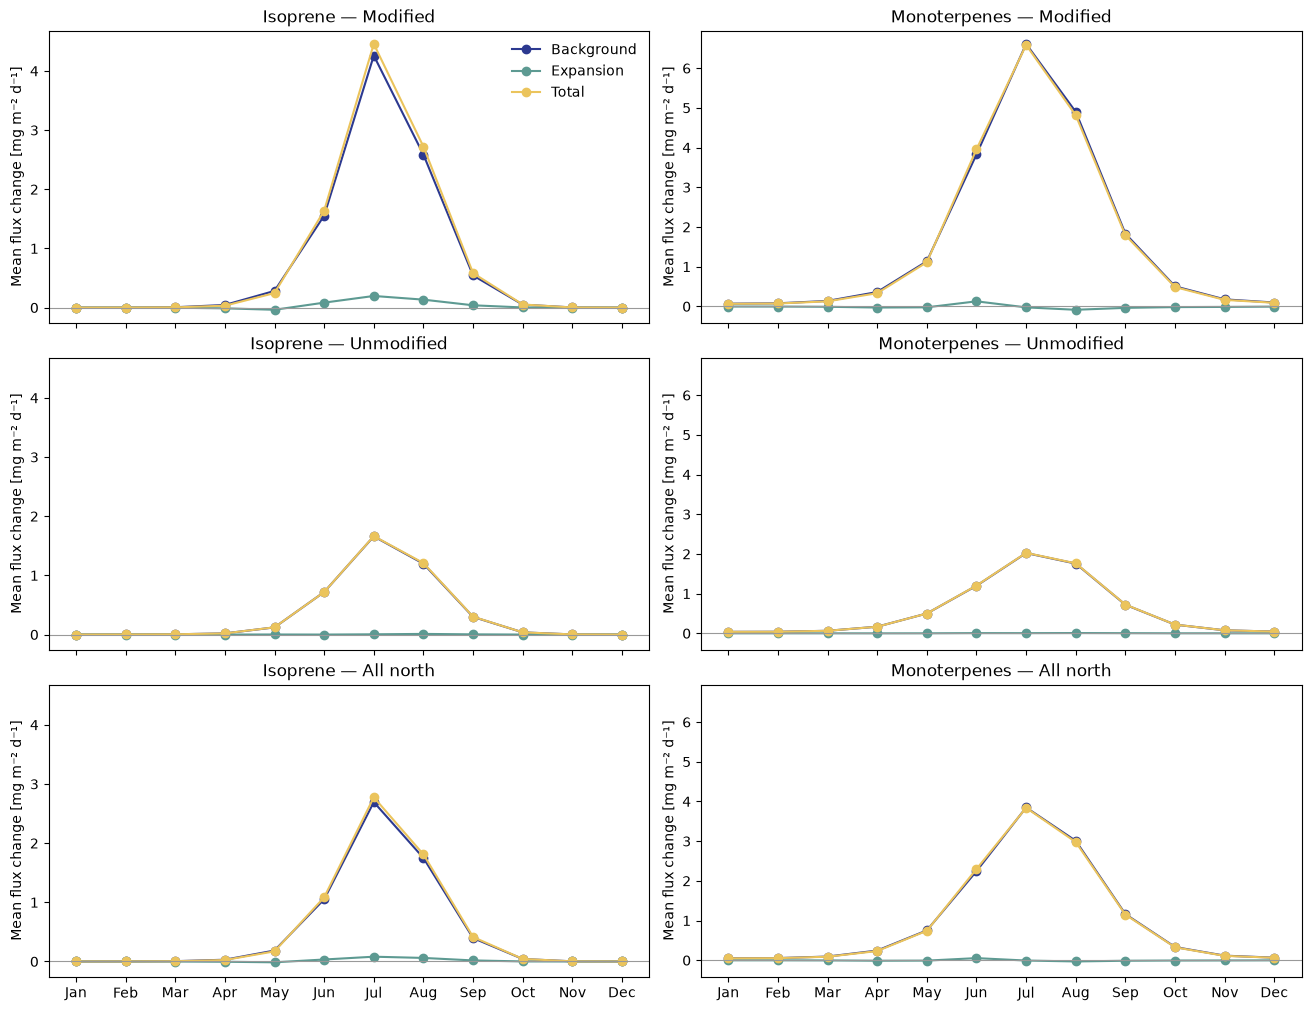

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, sharey="col", constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        for name in COMPARISONS:
            values = seasonal[var].sel(region=region, comparison=name)
            ax.plot(values.month, values, "o-", color=COLORS[name], label=name)
        ax.axhline(0, color="0.6", linewidth=0.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Mean flux change [mg m⁻² d⁻¹]",
               xticks=range(1, 13), xticklabels=list(calendar.month_abbr)[1:])
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "seasonality_three_regions.png", dpi=200)
plt.show()


## 8. Check cancellation within each region
Positive and negative annual-mean grid-cell changes are integrated separately. Their sum equals the net regional change. This diagnoses **spatial** cancellation after time averaging; it does not measure seasonal cancellation at a cell.

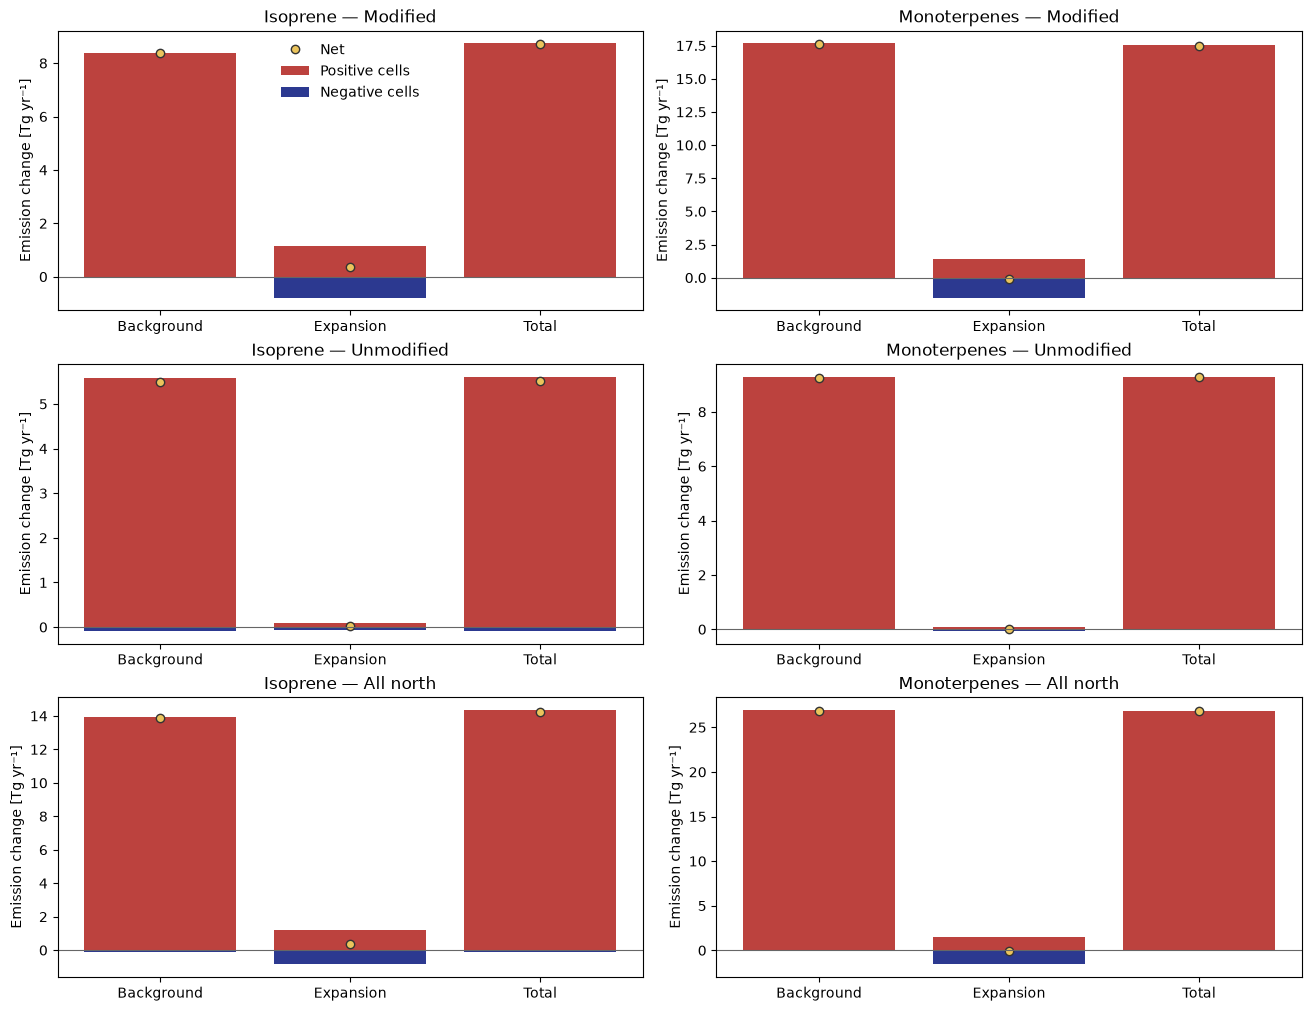

In [10]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
mean_annual_mass = (xr.concat(list(delta.values()), pd.Index(COMPARISONS, name="comparison")) *
                    seconds / 1e9).groupby("year").sum("time").mean("year")
positive = (mean_annual_mass.clip(min=0) * region_weights).sum(("lat", "lon"))
negative = (mean_annual_mass.clip(max=0) * region_weights).sum(("lat", "lon"))
net = annual.sel(comparison=COMPARISONS).mean("year")
xr.testing.assert_allclose(positive + negative, net)

cancellation = xr.concat([positive, negative, net], pd.Index(["Positive", "Negative", "Net"], name="component"))
cancellation.to_dataframe().to_csv(OUT / "spatial_cancellation_three_regions.csv")
fig, axes = plt.subplots(3, 2, figsize=(13, 10), constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        ax.bar(COMPARISONS, positive[var].sel(region=region), color="#BC423E", label="Positive cells")
        ax.bar(COMPARISONS, negative[var].sel(region=region), color="#2C3990", label="Negative cells")
        ax.plot(COMPARISONS, net[var].sel(region=region), "o", color=GOLD, mec="0.2", label="Net")
        ax.axhline(0, color="0.4", linewidth=0.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Emission change [Tg yr⁻¹]")
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "spatial_cancellation_three_regions.png", dpi=200)
plt.show()

## 9. Optional region map
Red = modified; light grey = unmodified. Both are restricted to the northern domain. Cartopy may need a pre-populated coastline cache on an offline cluster.

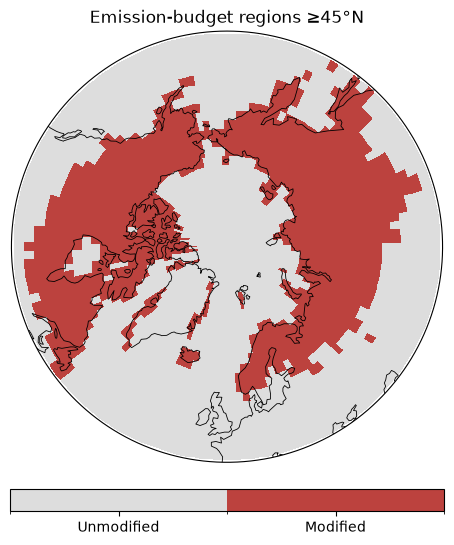

In [11]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
if RUN_MAPS:
    import cartopy.crs as ccrs
    from cartopy.util import add_cyclic_point
    from matplotlib.colors import ListedColormap
    from matplotlib.path import Path as MplPath
    
    classes = xr.where(modified, 1, 0).where(north).transpose("lat", "lon")
    cyclic, longitude = add_cyclic_point(classes.values, coord=classes.lon.values)
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": ccrs.NorthPolarStereo()})
    mesh = ax.pcolormesh(longitude, classes.lat, cyclic, transform=ccrs.PlateCarree(),
                         cmap=ListedColormap(["#dddddd", "#BC423E"]),
                         norm=BoundaryNorm([-0.5, 0.5, 1.5], 2), shading="auto")
    theta = np.linspace(0, 2 * np.pi, 200)
    circle = MplPath(np.column_stack([np.sin(theta), np.cos(theta)]) * 0.5 + 0.5)
    ax.set_boundary(circle, transform=ax.transAxes)
    ax.set_extent([-180, 180, MIN_LAT, 90], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.6)
    ax.set_title(f"Emission-budget regions ≥{MIN_LAT}°N")
    cb = fig.colorbar(mesh, ax=ax, orientation="horizontal", ticks=[0, 1], shrink=0.8, pad=0.05)
    cb.ax.set_xticklabels(["Unmodified", "Modified"])
    fig.savefig(OUT / "region_mask.png", dpi=200, bbox_inches="tight")
    plt.show()


## 9b. Background, expansion and total maps
Annual-mean flux change for each comparison (mean of the yearly means). Each species uses one colour scale shared by the three maps, set at the 98th percentile of |change| ≥45°N, so the most extreme cells saturate (colourbar extensions). **Hatched = not significant** (paired yearly t-test, FDR α = 0.10 over the cells ≥45°N). Section 12 repeats the expansion map on its own scale.

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:644: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:644: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:644: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axi

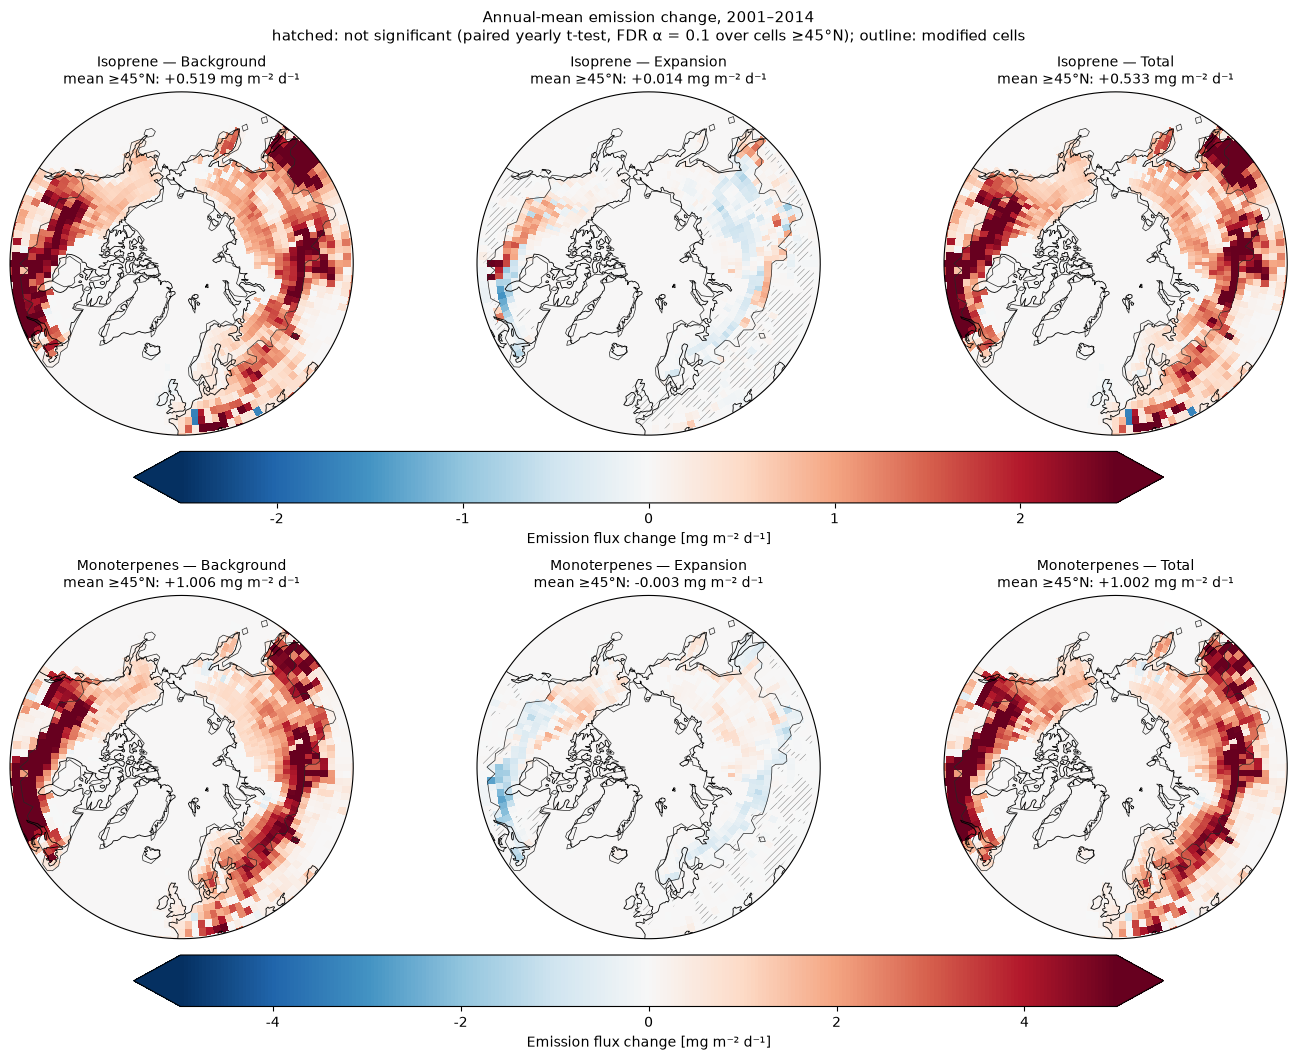

In [12]:
if RUN_MAPS:
    weights = region_weights.sel(region="All north", drop=True)
    yearly_maps = {name: yearly_mean(ds) * 86400 * 1e6 for name, ds in delta.items()}  # mg m-2 d-1
    fig, axes = plt.subplots(2, 3, figsize=(14, 10.5),
                             subplot_kw={"projection": ccrs.NorthPolarStereo()}, constrained_layout=True)
    for row, var in enumerate(VARS):
        means = {name: ym[var].mean("year") for name, ym in yearly_maps.items()}
        pooled = np.concatenate([m.where(north).values.ravel() for m in means.values()])
        limit = max(float(np.nanquantile(np.abs(pooled), MAP_QUANTILE)), 1e-12)
        for col, (name, field) in enumerate(means.items()):
            mean = float((field * weights).sum() / weights.sum())
            mesh = draw_map(axes[row, col], field, limit, nonsignificant(yearly_maps[name][var], north),
                            f"{LABELS[var]} — {name}\nmean ≥{MIN_LAT}°N: {mean:+.3f} mg m⁻² d⁻¹")
        add_cbar(fig, list(axes[row]), mesh, limit, "Emission flux change [mg m⁻² d⁻¹]")
    fig.suptitle(f"Annual-mean emission change, {START_YEAR}–{END_YEAR}\n{HATCH_NOTE}", fontsize=11)
    fig.savefig(OUT / "emissions_decomposition_maps.png", dpi=200)
    plt.show()

## Reading the results

1. Start with regional budget contributions. Does the negative expansion total arise within modified cells, outside them, or both?
2. Compare regional totals with mean fluxes. Large unmodified-area totals can arise from small flux changes over a large area.
3. Use the seasonal curves to locate the active months, and annual curves to check sign consistency.
4. Inspect the cancellation panels before describing a region as uniformly increasing or decreasing.
5. An expansion contrast outside modified cells can reflect environmental adjustments; these plots alone do not establish their mechanism or exclude other simulation differences.
6. Modified-cell results include all processes operating there. They are not a direct PFT-only attribution.
7. Error bars show interannual SD, not formal significance. Cloud/aerosol/radiation effects should still be evaluated over a wider domain.
8. The prescribed-PD experiment's emissions should be checked against realised SFISOP/SFMTERP if exact correspondence with this interactive-run decomposition is needed.

All CSVs and figures are saved in the single OUT folder configured above. No extra data loading is needed when rerunning plots.

## 10. Conclusions from the northern decomposition

Run 7 Nov 2026 on the new (CO₂-fix) chain, 2001–2014, ≥45°N. Numbers from `emissions_summary_three_regions.csv` and `spatial_cancellation_three_regions.csv`; ± = interannual SD of the 14 yearly values. Background = CTRL_FUT − CTRL_PD, Expansion = LCC_FUT − CTRL_FUT, Total = LCC_FUT − CTRL_PD.

| Tg yr⁻¹, ≥45°N | CTRL_PD | CTRL_FUT | LCC_FUT | Background | Expansion | Total |
|---|---|---|---|---|---|---|
| Isoprene | 9.36 | 23.22 | 23.61 | **+13.86 ± 0.78** | **+0.39 ± 0.17** | +14.25 |
| Monoterpenes | 8.34 | 35.21 | 35.12 | **+26.87 ± 1.02** | **−0.09 ± 0.22** | +26.78 |

1. **The future background dominates (a).** CTRL_FUT emits 2.5× (isoprene) and 4.2× (monoterpenes) more than CTRL_PD north of 45°N. Forest expansion adds ~3 % of the background change for isoprene and nothing measurable for monoterpenes.
2. **The expansion effect is small and, for isoprene, positive (a).** Isoprene +0.39 Tg yr⁻¹ (+1.7 % of CTRL_FUT); monoterpenes −0.09 Tg yr⁻¹, within its interannual SD (0.22), so not distinguishable from zero (b: paired t ≈ 1.6 with 14 years). The large negative FUT expansion contribution of the old (CO₂-bug) chain is gone.
3. **It sits in the modified cells (a).** Isoprene +0.36 of the +0.39 Tg yr⁻¹; monoterpenes −0.12 there and +0.03 in the unmodified cells (60 % of the northern area).
4. **The small net hides large opposite changes (a).** In the modified cells, expansion raises emissions in some cells and lowers them in others: isoprene +1.14 / −0.78 Tg yr⁻¹ (net +0.36), monoterpenes +1.38 / −1.50 (net −0.12). Each one-sided change is 2–13× the net, so the sign of the net depends on the balance between regions, not on a uniform response.
5. **Where the decreases are (a, §11):** 80 % of the gross decrease comes from 140 cells for isoprene (134 modified) and 119 for monoterpenes (all modified). The largest are around 48–52°N, 270–290°E (eastern Canada) and 50–52°N, 105–112°E (southern Siberia).

Not shown here: whether the cell-level increases and decreases come from PFT composition, LAI or temperature. §14–15 give candidate drivers, not an attribution.


## 11. Where does the negative expansion contribution originate?
Ranks annual-mean negative grid-cell contributions, including cell area. Hotspots supply 80% of the gross decrease. They are outcome-selected, species-specific diagnostic regions, not independent evidence of mechanism.

Isoprene: 140 cells supply 80% of gross decrease: 134 modified and 6 unmodified.


,lat,lon,change_Tg_yr,gross_decrease_Tg_yr,cumulative_fraction
0,50.21053,282.5,-0.02067,0.02067,0.02457
1,50.21053,280.0,-0.01880,0.01880,0.04691
2,50.21053,285.0,-0.01733,0.01733,0.06751
3,50.21053,287.5,-0.01526,0.01526,0.08564
4,50.21053,112.5,-0.01258,0.01258,0.10059
5,52.10526,272.5,-0.01223,0.01223,0.11513
6,50.21053,290.0,-0.01074,0.01074,0.12789
7,52.10526,282.5,-0.01069,0.01069,0.14059
8,50.21053,277.5,-0.01069,0.01069,0.15328
9,48.31579,305.0,-0.01011,0.01011,0.16529


Monoterpenes: 119 cells supply 80% of gross decrease: 119 modified and 0 unmodified.


,lat,lon,change_Tg_yr,gross_decrease_Tg_yr,cumulative_fraction
0,48.31579,275.0,-0.03868,0.03868,0.02479
1,50.21053,282.5,-0.03628,0.03628,0.04805
2,50.21053,285.0,-0.03137,0.03137,0.06816
3,50.21053,280.0,-0.03072,0.03072,0.08785
4,50.21053,287.5,-0.02883,0.02883,0.10632
5,50.21053,270.0,-0.02656,0.02656,0.12335
6,50.21053,275.0,-0.02613,0.02613,0.14010
7,52.10526,282.5,-0.02583,0.02583,0.15665
8,48.31579,290.0,-0.02435,0.02435,0.17226
9,50.21053,272.5,-0.02371,0.02371,0.18746


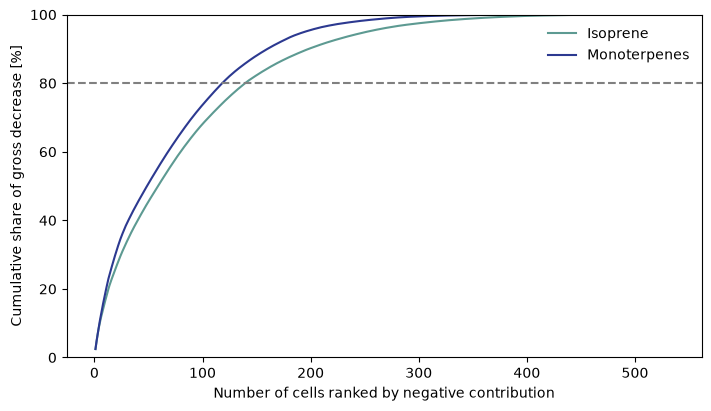

In [13]:
hotspots, ranked_cells = {}, {}
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for var in VARS:
    contribution = (mean_annual_mass[var].sel(comparison="Expansion", drop=True) * area).where(north)
    table = contribution.to_dataframe(name="change_Tg_yr").reset_index()
    table = table.loc[table.change_Tg_yr < 0].sort_values("change_Tg_yr").reset_index(drop=True)
    if table.empty:
        print(f"{LABELS[var]}: no negative annual-mean cells.")
        continue
    table["gross_decrease_Tg_yr"] = -table.change_Tg_yr
    table["cumulative_fraction"] = table.gross_decrease_Tg_yr.cumsum() / table.gross_decrease_Tg_yr.sum()
    n80 = int(np.searchsorted(table.cumulative_fraction.values, .8) + 1)
    hot = xr.zeros_like(modified, dtype=bool)
    for row in table.iloc[:n80].itertuples():
        hot.loc[dict(lat=row.lat, lon=row.lon)] = True
    hotspots[var], ranked_cells[var] = hot, table
    table.to_csv(OUT / f"{var}_negative_cells_ranked.csv", index=False)
    n_modified = int((hot & modified).sum())
    print(f"{LABELS[var]}: {n80} cells supply 80% of gross decrease: "
          f"{n_modified} modified and {n80 - n_modified} unmodified.")
    display(table.head(10).round(5))
    ax.plot(np.arange(1, len(table) + 1), table.cumulative_fraction * 100, label=LABELS[var],
            color=[TEAL, NAVY][VARS.index(var)])
ax.axhline(80, color="0.5", linestyle="--")
ax.set(xlabel="Number of cells ranked by negative contribution",
       ylabel="Cumulative share of gross decrease [%]", ylim=(0, 100))
if ranked_cells:
    ax.legend(frameon=False)
fig.savefig(OUT / "negative_contribution_concentration.png", dpi=200)
plt.show()

## 12. Expansion maps on a narrower scale (optional Cartopy)
Each species uses its own 98th percentile of absolute northern flux change as its colour limit. Extreme cells saturate; colourbar extensions indicate this. **Hatched = not significant** (paired yearly t-test, FDR α = 0.10); dark outline = modified cells.

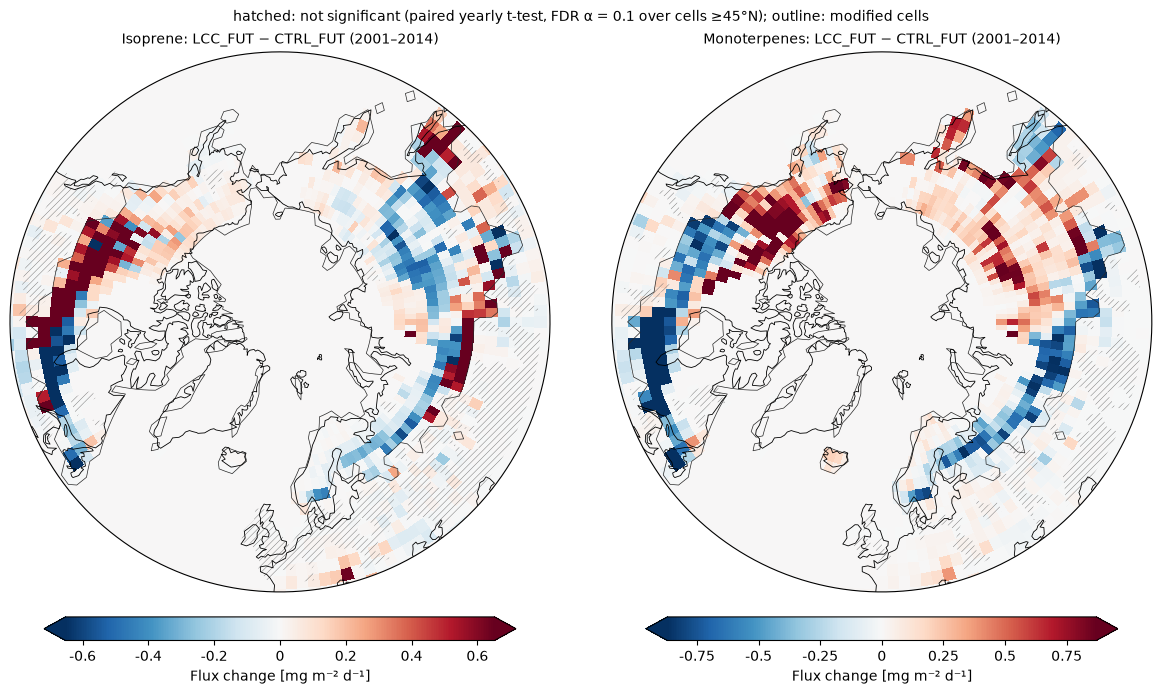

In [14]:
if RUN_MAPS:
    yearly_exp = yearly_mean(delta["Expansion"]) * 86400 * 1e6
    fig, axes = plt.subplots(1, 2, figsize=(12, 6.8),
                             subplot_kw={"projection": ccrs.NorthPolarStereo()}, constrained_layout=True)
    for ax, var in zip(axes, VARS):
        field = yearly_exp[var].mean("year")
        limit = max(float(np.nanquantile(np.abs(field.where(north).values), .98)), 1e-12)
        mesh = draw_map(ax, field, limit, nonsignificant(yearly_exp[var], north),
                        f"{LABELS[var]}: LCC_FUT − CTRL_FUT ({START_YEAR}–{END_YEAR})")
        add_cbar(fig, ax, mesh, limit, "Flux change [mg m⁻² d⁻¹]")
    fig.suptitle(HATCH_NOTE, fontsize=10)
    fig.savefig(OUT / "expansion_maps_narrow_scale.png", dpi=200)
    plt.show()

## 13. Additional inputs
Paths for sections 14–17 (new chain). TREFHT is 2-m air temperature, not MEGAN leaf temperature; CLM `TV` (vegetation temperature) is the closer proxy. Additional fields must be monthly 2D gridded fields with time bounds on the CAM grid.

All fBVOC runs prescribe **all 19 MEGAN species** (2001–2014 climatology of the source run, relabelled to 2100), not only ISOP/MTERP as the old `_IM` runs did. SOA: the new chain writes the model SOA column burdens `cb_SOA_A1`, `cb_SOA_NA` (interstitial) and `_OCW` (cloud-borne); `cb_SOA_LV/SV` are the gas-phase precursor columns.

In [15]:
CLM_FILES = {"CTRL_FUT": CLM["CTRL_FUT"], "LCC_FUT": CLM["LCC_FUT"]}

RUN_MECHANISMS = True
MECHANISM_INPUTS = {
    "TREFHT": {"CTRL_FUT": FILES["CTRL_FUT"], "LCC_FUT": FILES["LCC_FUT"]},  # CAM 2-m air temperature
    "FSDS": {"CTRL_FUT": FILES["CTRL_FUT"], "LCC_FUT": FILES["LCC_FUT"]},    # CAM surface downwelling SW
    "TV": CLM_FILES,    # CLM vegetation temperature (closer to MEGAN leaf temperature than TREFHT)
    "TLAI": CLM_FILES,  # CLM total leaf area index
}
SURFDATA = {
    "CTRL_FUT": "/cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/release-clm5.0.18/surfdata_1.9x2.5_hist_78pfts_CMIP6_simyr2000_c190304.nc",
    "LCC_FUT": "/cluster/shared/noresm/inputdata/lnd/clm2/surfdata_map/surfdata_1.9x2.5_SSP5-8.5_2100_78pfts_LPJGUESS.nc",
}  # fsurdat from each case's CaseDocs/lnd_in (unchanged in the new chain)
# Fixed-emission runs and the run whose emissions each one prescribes
FIXED_SOURCE = {"LCC_FUT_fBVOCctrlPD": "CTRL_PD", "LCC_FUT_fBVOCctrlFUT": "CTRL_FUT",
                "LCC_FUT_fBVOClccPD": "LCC_PD"}
FIXED_FILES = {alias: CAM[alias] for alias in FIXED_SOURCE}
# Monthly 2D CAM h0 fields. cb_SOA_A1/NA = model SOA burdens (interstitial), _OCW = cloud-borne;
# cb_SOA_LV/SV = gas-phase SOA precursor columns.
ATM_VARIABLES = ["cb_ISOP", "cb_MTERP", "cb_SOA_LV", "cb_SOA_SV", "cb_SOA_A1", "cb_SOA_NA",
                 "cb_SOA_A1_OCW", "cb_SOA_NA_OCW", "AOD_VIS", "CDNUMC", "ACTREL",
                 "TGCLDLWP", "CLDTOT", "SWCF", "LWCF", "FSNT", "FLNT"]
ATM_CASES = ["LCC_FUT", "LCC_FUT_fBVOCctrlPD", "LCC_FUT_fBVOCctrlFUT", "CTRL_FUT", "CTRL_FUT_fBVOCctrlFUT"]

In [16]:
def _read_monthly_file(args):
    """One raw h0 file -> (chunk, durations, units) of the selected months, or None. Same checks as before."""
    path, variables, expected = args
    with xr.open_dataset(path) as ds:
        missing = [v for v in variables if v not in ds]
        if missing:
            raise KeyError(f"{missing} not found in {path}")
        bounds = ds.time.attrs.get("bounds")
        if not bounds or bounds not in ds:
            bounds = next((v for v in ("time_bnds", "time_bounds") if v in ds), None)
        if bounds is None:
            raise ValueError(f"{path}: complete monthly time bounds are required.")
        indices, keys, dt = [], [], []
        for i in range(ds.sizes["time"]):
            start, end = ds[bounds].isel(time=i).values.ravel()
            sy, sm, sd, sh, smin, ss = date_parts(start)
            ey, em, ed, eh, emin, es = date_parts(end)
            year, month, *_ = date_parts(start + (end - start) / 2)
            key = year * 100 + month
            if key not in expected:
                continue
            if not (sd == ed == 1 and (ey, em) == (sy + (sm == 12), sm % 12 + 1)
                    and (sy, sm) == (year, month) and sh == smin == ss == eh == emin == es == 0):
                raise ValueError(f"{path}: record {i} is not a complete month.")
            indices.append(i)
            keys.append(key)
            dt.append(seconds_between(start, end))
        if not indices:
            return None
        for v in variables:
            if set(ds[v].dims) != {"time", "lat", "lon"}:
                raise ValueError(f"{v}: expected time/lat/lon, got {ds[v].dims}")
        units = {v: ds[v].attrs.get("units", "") for v in variables}
        return (ds[variables].isel(time=indices).assign_coords(time=keys).load(),
                xr.DataArray(dt, dims="time", coords={"time": keys}), units)


def _load_monthly_uncached(pattern, variables):
    """Monthly 2D fields (time, lat, lon) of several variables; files read 8 at a time."""
    paths = sorted(glob(str(Path(pattern).expanduser())))
    if not paths:
        raise FileNotFoundError(pattern)
    chunks, durations, units_seen = [], [], {v: set() for v in variables}
    expected = reference.time.values
    for out in parallel_map(_read_monthly_file, [(path, list(variables), set(expected)) for path in paths]):
        if out is None:
            continue
        chunk, dur, units = out
        for v in variables:
            units_seen[v].add(units[v])
        chunks.append(chunk)
        durations.append(dur)
    if not chunks:
        raise ValueError(f"No selected months in {pattern}.")
    data = xr.concat(chunks, dim="time", join="exact").sortby("time").sortby("lat").sortby("lon")
    dt = xr.concat(durations, dim="time").sortby("time")
    if not np.array_equal(data.time.values, expected):
        raise ValueError(f"{pattern}: missing or duplicate months.")
    np.testing.assert_allclose(dt.values, seconds.values, rtol=0, atol=0)
    # CLM and CAM write the same grid with ~1e-13° differences: check, then use the CAM coordinates.
    np.testing.assert_allclose(data.lat.values, reference.lat.values, rtol=0, atol=1e-5)
    np.testing.assert_allclose(data.lon.values, reference.lon.values, rtol=0, atol=1e-5)
    data = data.assign_coords(lat=reference.lat, lon=reference.lon)
    for v in variables:
        if len(units_seen[v]) != 1 or not next(iter(units_seen[v])):
            raise ValueError(f"{v}: missing or inconsistent units: {units_seen[v]}")
        data[v].attrs["units"] = next(iter(units_seen[v]))
    return data.assign_coords(year=reference.year, month=reference.month)


_MONTHLY_CACHE = {}  # (pattern, variable) -> DataArray: each run's variables are read from disk once


def load_monthly_dataset(pattern, variables):
    """Monthly 2D fields (time, lat, lon) of several variables; only variables not yet read are loaded."""
    variables = list(variables)
    todo = [v for v in variables if (pattern, v) not in _MONTHLY_CACHE]
    if todo:
        fresh = _load_monthly_uncached(pattern, todo)
        for v in todo:
            _MONTHLY_CACHE[pattern, v] = fresh[v]
    return xr.Dataset({v: _MONTHLY_CACHE[pattern, v] for v in variables})


def load_monthly_field(pattern, variable):
    return load_monthly_dataset(pattern, [variable])[variable]


def regional_series(field, mask):
    finite = np.isfinite(field)
    always_valid, ever_valid = finite.all("time"), finite.any("time")
    if bool(((always_valid != ever_valid) & mask).any()):
        raise ValueError("Time-varying missing values inside the selected region.")
    w = area.where(mask & always_valid, 0)
    if float(w.sum()) <= 0:
        raise ValueError("No valid area in this region.")
    return (field.where(finite, 0) * w).sum(("lat", "lon")) / w.sum()


def paired_difference(a, b):
    a, b = xr.align(a, b, join="exact")
    if a.attrs.get("units") != b.attrs.get("units"):
        raise ValueError("Units differ between paired fields.")
    if not bool((np.isfinite(a) == np.isfinite(b)).all()):
        raise ValueError("Paired fields have different missing-data footprints.")
    return a - b

## 14. Environmental controls in the main decrease regions
Plots seasonal contrasts and exports JJA means. Land-only fields use their valid land-cell footprint, so their area denominator can differ from that of CAM fields. Missing-data masks must match between cases and remain stable in time. Coincident changes are hypotheses for mechanism, not causal attribution.

Loading ['TREFHT', 'FSDS'] from NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028
Loading ['TREFHT', 'FSDS'] from NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028
Loading ['TV', 'TLAI'] from NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028
Loading ['TV', 'TLAI'] from NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028


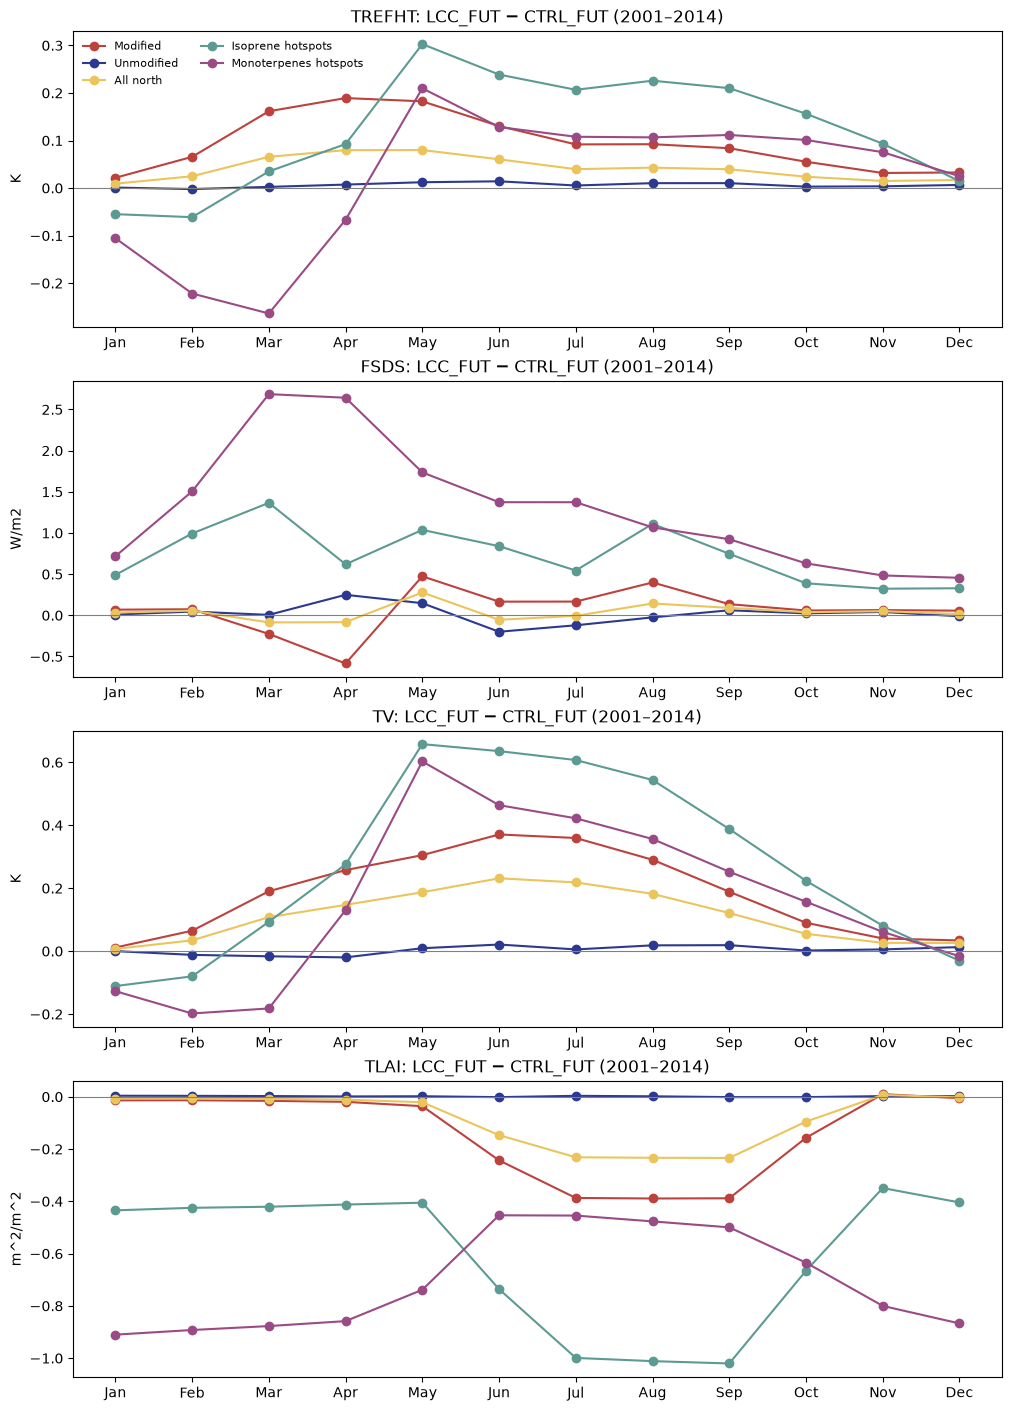

,variable,region,JJA_change,units
0,TREFHT,Modified,0.104531,K
1,TREFHT,Unmodified,0.009897,K
2,TREFHT,All north,0.047551,K
3,TREFHT,Isoprene hotspots,0.223560,K
4,TREFHT,Monoterpenes hotspots,0.114110,K
5,FSDS,Modified,0.244806,W/m2
6,FSDS,Unmodified,-0.114296,W/m2
7,FSDS,All north,0.028589,W/m2
8,FSDS,Isoprene hotspots,0.831226,W/m2
9,FSDS,Monoterpenes hotspots,1.270594,W/m2


In [17]:
mechanism = {}
if RUN_MECHANISMS:
    by_path = {}
    for variable, paths in MECHANISM_INPUTS.items():
        for case, pattern in paths.items():
            by_path.setdefault(pattern, []).append(variable)
    loaded = {}
    for pattern, variables in by_path.items():
        print(f"Loading {variables} from {pattern.split('/')[-4]}")
        loaded[pattern] = load_monthly_dataset(pattern, variables)
    mechanism = {variable: {case: loaded[pattern][variable] for case, pattern in paths.items()}
                 for variable, paths in MECHANISM_INPUTS.items()}
else:
    print("Mechanism loading skipped; set RUN_MECHANISMS=True to enable.")

diagnostic_masks = {r: region_masks.sel(region=r, drop=True) for r in REGIONS}
diagnostic_masks.update({f"{LABELS[var]} hotspots": mask for var, mask in hotspots.items()})
MASK_COLORS = {**REGION_COLORS, "Isoprene hotspots": TEAL, "Monoterpenes hotspots": PLUM}
mechanism_rows = []
if mechanism:
    fig, axes = plt.subplots(len(mechanism), 1, figsize=(10, 3.5 * len(mechanism)),
                              squeeze=False, constrained_layout=True)
    for ax, (variable, pair) in zip(axes[:, 0], mechanism.items()):
        difference = paired_difference(pair["LCC_FUT"], pair["CTRL_FUT"])
        units = pair["CTRL_FUT"].attrs["units"]
        for name, mask in diagnostic_masks.items():
            series = regional_series(difference, mask)
            cycle = (series * seconds).groupby("month").sum() / seconds.groupby("month").sum()
            ax.plot(cycle.month, cycle, marker="o", label=name, color=MASK_COLORS[name])
            jja = reference.month.isin([6, 7, 8])
            jja_mean = float((series * seconds).where(jja).sum() / seconds.where(jja).sum())
            mechanism_rows.append({"variable": variable, "region": name, "JJA_change": jja_mean, "units": units})
        ax.axhline(0, color="0.5", linewidth=.8)
        ax.set(title=f"{variable}: LCC_FUT − CTRL_FUT ({START_YEAR}–{END_YEAR})", ylabel=units,
               xticks=range(1, 13), xticklabels=list(calendar.month_abbr)[1:])
    axes[0, 0].legend(frameon=False, fontsize=8, ncol=2)
    fig.savefig(OUT / "mechanism_seasonal_changes.png", dpi=200)
    plt.show()
    mechanism_summary = pd.DataFrame(mechanism_rows)
    display(mechanism_summary)
    mechanism_summary.to_csv(OUT / "mechanism_JJA_changes.csv", index=False)

## 15. PFT-fraction changes (optional)
Uses the actual control and LCC surface datasets. Verifies their 2D geography before attaching CAM coordinates. This block expects the original grid order; if it differs it stops, rather than silently relabelling cells.

Reported values are whole-grid-area-weighted changes in **natural-PFT percentages**, not changes in PFT area (km²). PFT area calculation would additionally require the natural-vegetation fraction and the correct land-area basis.

In [18]:
if all(SURFDATA.values()):
    pft = {}
    for case, path in SURFDATA.items():
        with xr.open_dataset(path) as ds:
            field = ds["PCT_NAT_PFT"].load()
            rename = {d: new for d, new in {"lsmlat": "lat", "lsmlon": "lon"}.items() if d in field.dims}
            field = field.rename(rename)
            if "LATIXY" not in ds or "LONGXY" not in ds:
                raise ValueError("LATIXY/LONGXY required to verify the surfdata grid.")
            lat2, lon2 = ds.LATIXY.values, np.mod(ds.LONGXY.values, 360)
            expected_shape = (reference.sizes["lat"], reference.sizes["lon"])
            if lat2.shape != expected_shape or lon2.shape != expected_shape:
                raise ValueError("Surface-data grid dimensions do not match CAM.")
            np.testing.assert_allclose(lat2, np.broadcast_to(reference.lat.values[:, None], expected_shape), rtol=0, atol=1e-5)
            np.testing.assert_allclose(lon2, np.broadcast_to(reference.lon.values[None, :] % 360, expected_shape), rtol=0, atol=1e-5)
            pft[case] = field.assign_coords(lat=reference.lat, lon=reference.lon)
    ctrl, lcc = xr.align(pft["CTRL_FUT"], pft["LCC_FUT"], join="exact")
    change = lcc - ctrl
    w = region_weights.sel(region="Modified", drop=True)
    if not bool(np.isfinite(change.where(w > 0, 0)).all()):
        raise ValueError("Missing PFT fractions within modified cells.")
    mean_change = (change * w).sum(("lat", "lon")) / w.sum()
    pft_summary = mean_change.to_dataframe(name="mean_change_percentage_points")
    display(pft_summary)
    pft_summary.to_csv(OUT / "PFT_changes_modified_cells.csv")
else:
    print("PFT analysis skipped: set both SURFDATA paths.")


,mean_change_percentage_points
natpft,
0,-3.501225
1,0.000701
2,2.345383
3,2.828949
4,0.000000
5,0.000154
6,0.000000
7,0.651382
8,4.836425


## 16. Realised fixed emissions versus their source controls
Checks annual northern/regional budgets, annual-mean map RMSE and monthly seasonal-cycle differences. Climatology construction and interpolation can produce differences; inspect their size rather than assuming exact monthwise equivalence. Budget agreement alone can hide spatial discrepancies. Sources: LCC_FUT_fBVOCctrlPD ← CTRL_PD, LCC_FUT_fBVOCctrlFUT ← CTRL_FUT, LCC_FUT_fBVOClccPD ← LCC_PD. The prescribed files are a 2001–2014 climatology, so the fixed runs have no interannual variability.

Loading LCC_FUT_fBVOCctrlPD
Loading LCC_FUT_fBVOCctrlFUT
Loading LCC_FUT_fBVOClccPD
Loading source LCC_PD


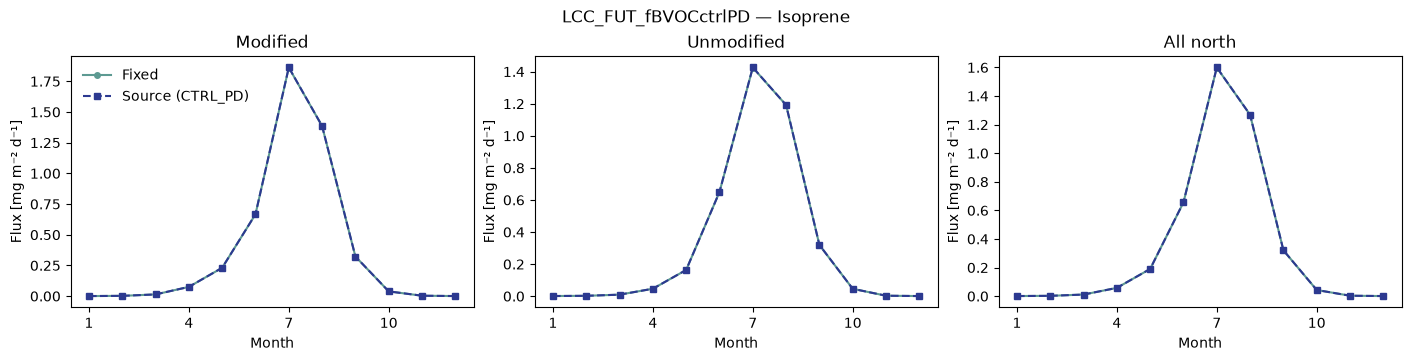

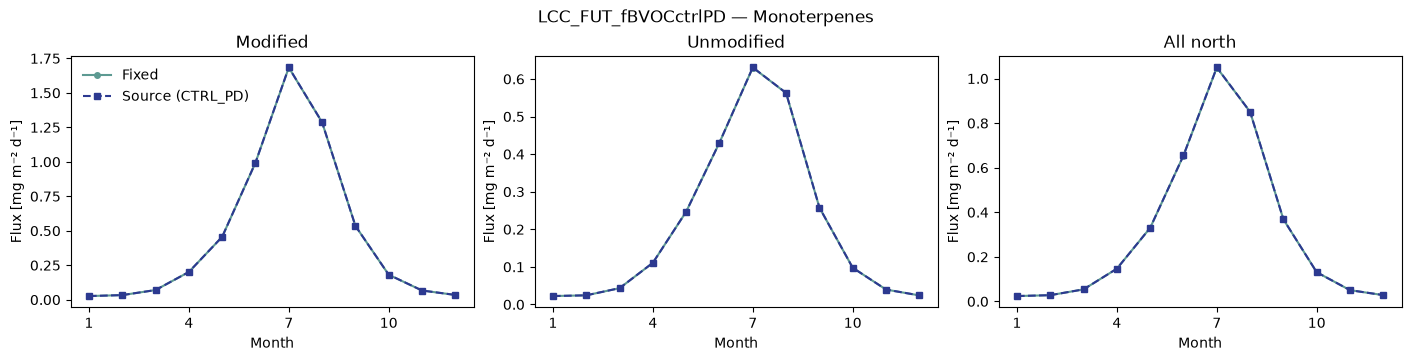

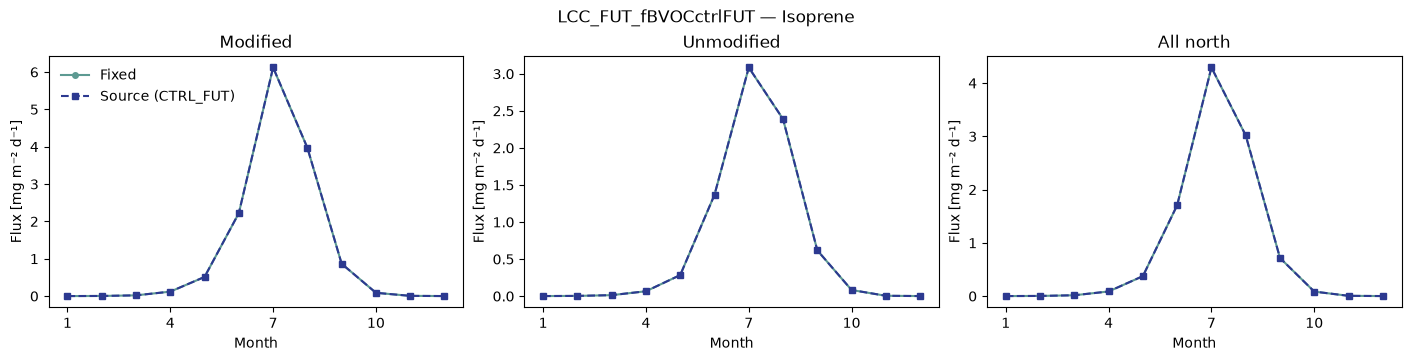

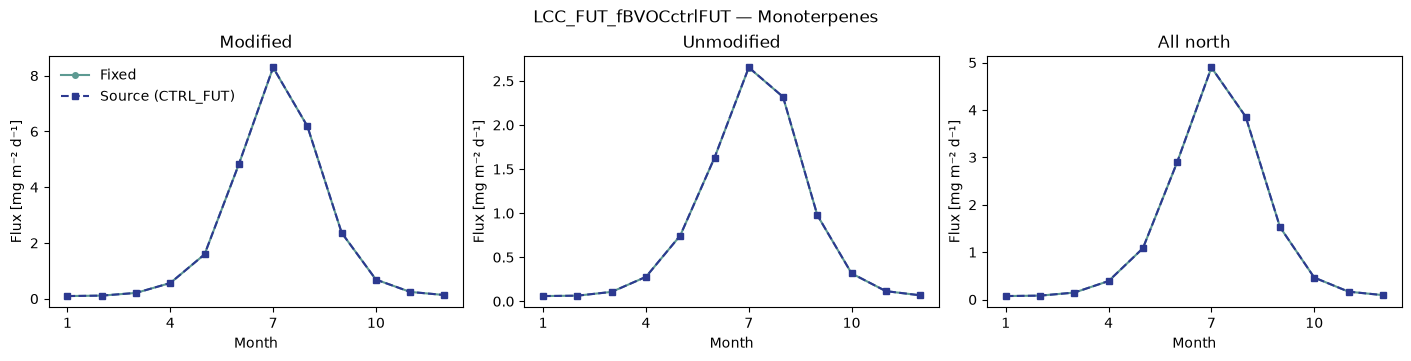

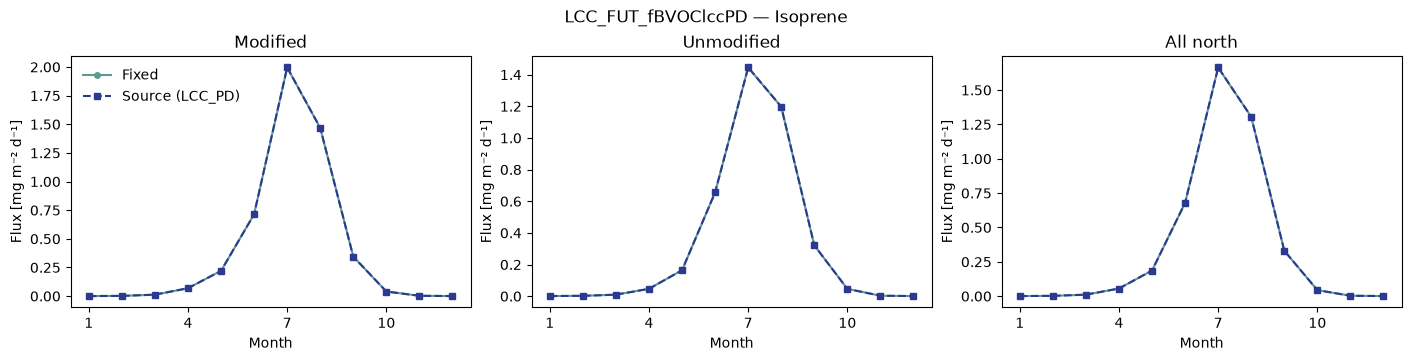

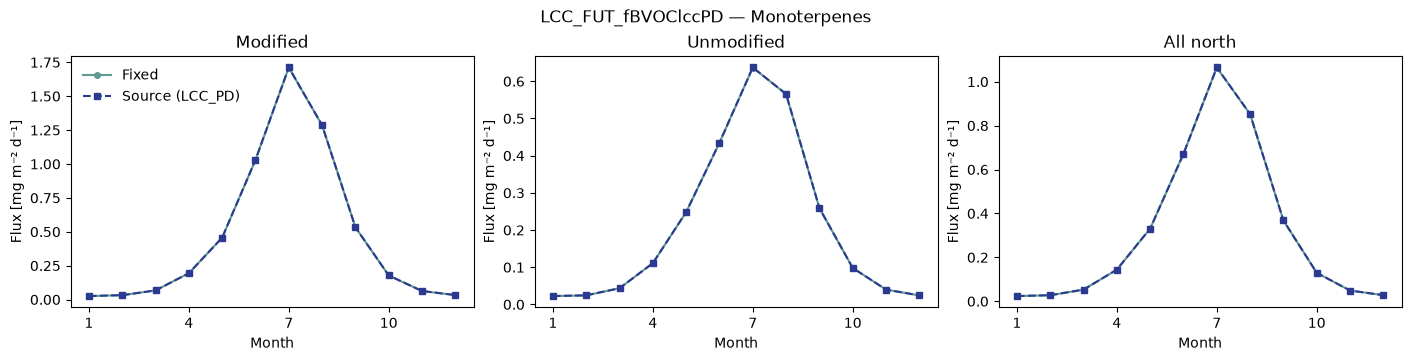

,case,source,species,region,fixed_Tg_yr,source_Tg_yr,difference_Tg_yr,difference_percent,mean_map_RMSE_mg_m2_day
0,LCC_FUT_fBVOCctrlPD,CTRL_PD,Isoprene,Modified,4.12396,4.12592,-0.00196,-0.04745,0.00033
1,LCC_FUT_fBVOCctrlPD,CTRL_PD,Isoprene,Unmodified,5.22965,5.23213,-0.00248,-0.04745,0.00041
2,LCC_FUT_fBVOCctrlPD,CTRL_PD,Isoprene,All north,9.35361,9.35805,-0.00444,-0.04745,0.00038
3,LCC_FUT_fBVOCctrlPD,CTRL_PD,Monoterpenes,Modified,4.97372,4.97608,-0.00236,-0.04744,0.00037
4,LCC_FUT_fBVOCctrlPD,CTRL_PD,Monoterpenes,Unmodified,3.36316,3.36476,-0.00160,-0.04744,0.00026
5,LCC_FUT_fBVOCctrlPD,CTRL_PD,Monoterpenes,All north,8.33688,8.34083,-0.00396,-0.04744,0.00031
6,LCC_FUT_fBVOCctrlFUT,CTRL_FUT,Isoprene,Modified,12.48438,12.49031,-0.00593,-0.04745,0.00092
7,LCC_FUT_fBVOCctrlFUT,CTRL_FUT,Isoprene,Unmodified,10.72748,10.73257,-0.00509,-0.04745,0.00087
8,LCC_FUT_fBVOCctrlFUT,CTRL_FUT,Isoprene,All north,23.21186,23.22288,-0.01102,-0.04745,0.00089
9,LCC_FUT_fBVOCctrlFUT,CTRL_FUT,Monoterpenes,Modified,22.58992,22.60065,-0.01072,-0.04744,0.00168


In [19]:
fixed_emissions = {}
for alias, pattern in FIXED_FILES.items():
    print(f"Loading {alias}")
    fixed_emissions[alias] = load_monthly_dataset(pattern, VARS)
sources = dict(fields)
for name in set(FIXED_SOURCE.values()) - set(sources):
    print(f"Loading source {name}")
    sources[name] = load_monthly_dataset(CAM[name], VARS)
check_rows = []
for alias, fixed in fixed_emissions.items():
    source = sources[FIXED_SOURCE[alias]]
    for var in VARS:
        unit = fixed[var].attrs.get("units", "").lower().replace(" ", "").replace("**", "^")
        if unit not in {"kg/m2/s", "kg/m^2/s", "kgm-2s-1", "kgm^-2s^-1"}:
            raise ValueError(f"{alias} {var}: expected kg m-2 s-1.")
        if not bool(np.isfinite(fixed[var]).all()):
            raise ValueError("Fixed emissions contain missing values.")
        fixed_mean = (fixed[var] * seconds).sum("time") / seconds.sum()
        source_mean = (source[var] * seconds).sum("time") / seconds.sum()
        fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
        for ax, region in zip(axes, REGIONS):
            w = region_weights.sel(region=region, drop=True)
            fixed_mass = float(((fixed[var] * w).sum(("lat", "lon")) * seconds / 1e9).groupby("year").sum().mean())
            source_mass = float(((source[var] * w).sum(("lat", "lon")) * seconds / 1e9).groupby("year").sum().mean())
            rmse = float(np.sqrt((((fixed_mean - source_mean) ** 2) * w).sum() / w.sum()))
            check_rows.append({"case": alias, "source": FIXED_SOURCE[alias], "species": LABELS[var],
                               "region": region, "fixed_Tg_yr": fixed_mass, "source_Tg_yr": source_mass,
                               "difference_Tg_yr": fixed_mass - source_mass,
                               "difference_percent": 100 * (fixed_mass - source_mass) / source_mass if source_mass else np.nan,
                               "mean_map_RMSE_mg_m2_day": rmse * 86400 * 1e6})
            for label, field, color, style in [("Fixed", fixed[var], TEAL, "o-"),
                                               (f"Source ({FIXED_SOURCE[alias]})", source[var], NAVY, "s--")]:
                series = (field * w).sum(("lat", "lon")) / w.sum() * 86400 * 1e6
                cycle = (series * seconds).groupby("month").sum() / seconds.groupby("month").sum()
                ax.plot(cycle.month, cycle, style, color=color, label=label, ms=4)
            ax.set(title=region, xlabel="Month", ylabel="Flux [mg m⁻² d⁻¹]", xticks=[1, 4, 7, 10])
        axes[0].legend(frameon=False)
        fig.suptitle(f"{alias} — {LABELS[var]}")
        fig.savefig(OUT / f"fixed_check_{alias}_{var}.png", dpi=200)
        plt.show()
fixed_check = pd.DataFrame(check_rows)
display(fixed_check.round(5))
fixed_check.to_csv(OUT / "fixed_emissions_vs_source.csv", index=False)

## 17. Atmospheric response decomposition over the northern domain
Monthly 2D SOA/cloud/radiation diagnostics from CAM h0. This notebook does not reconstruct cloud-conditioned diagnostics or Ghan terms.

Contrasts (all in the FUT background with expanded vegetation, except the artefact):
- **Full contrast** = LCC_FUT − LCC_FUT_fBVOCctrlPD.
- **LCC emissions effect** = LCC_FUT − LCC_FUT_fBVOCctrlFUT (interactive LCC emissions vs CTRL_FUT emissions).
- **PD→FUT prescribed emissions effect** = LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD.
- Identity: Full = LCC emissions effect + PD→FUT prescribed emissions effect (checked).
- **Prescription artefact** art_FUT = CTRL_FUT − CTRL_FUT_fBVOCctrlFUT (design B, matched baseline; interactive − prescribed, user 2026-11-07): computing the emissions interactively vs prescribing the run's own emissions.
- **LCC emissions effect, artefact-corrected** = (LCC_FUT − LCC_FUT_fBVOCctrlFUT) − art_FUT. It assumes art(LCC land) ≈ art(CTRL land), tested in PD only (`diagnostics/fbvoc-prescription-artefact/how_big_artefact_is_PD.ipynb`).

The identity is algebraic; it is not a claim of a linear atmospheric response. A prescribed climatology also lacks interannual and weather coupling. `p_paired_t` = paired t-test of the 14 yearly regional means (descriptive; no multiple-testing correction across the diagnostics). Ordinary CRE differences are not automatically aerosol–cloud forcing.

Loading LCC_FUT
Loading LCC_FUT_fBVOCctrlPD
Loading LCC_FUT_fBVOCctrlFUT
Loading CTRL_FUT
Loading CTRL_FUT_fBVOCctrlFUT


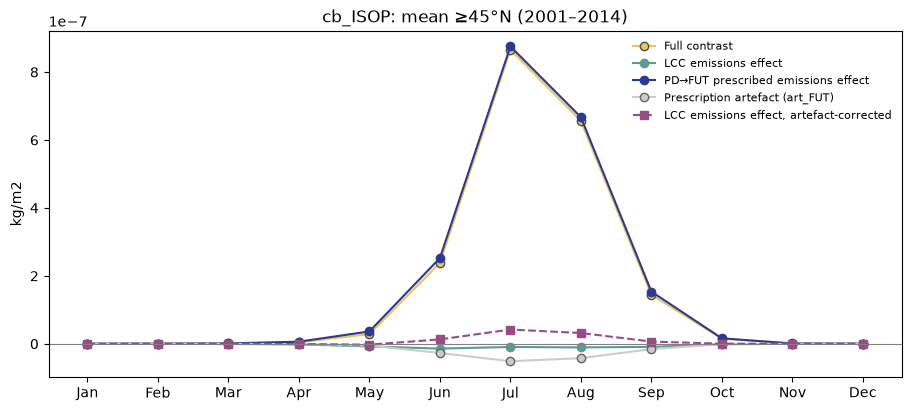

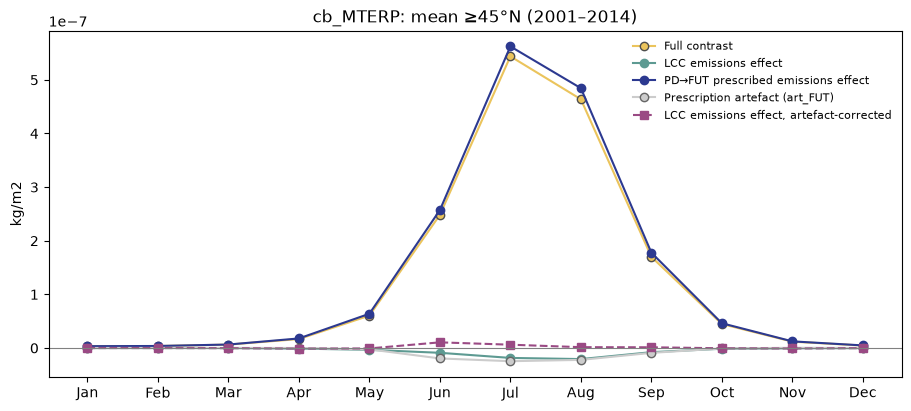

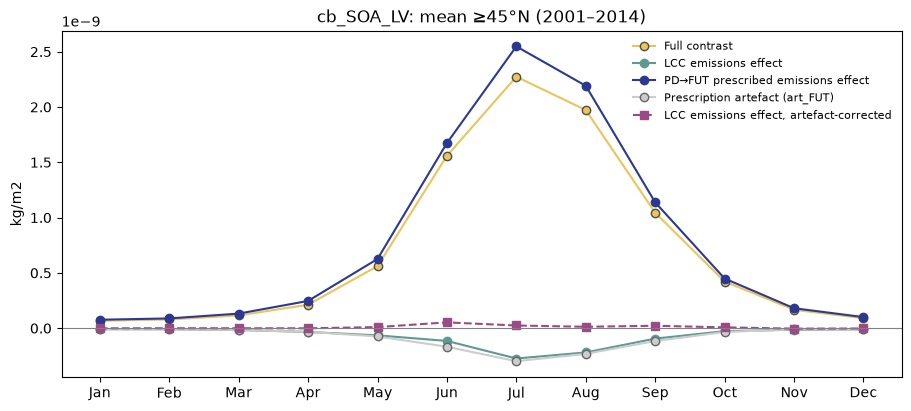

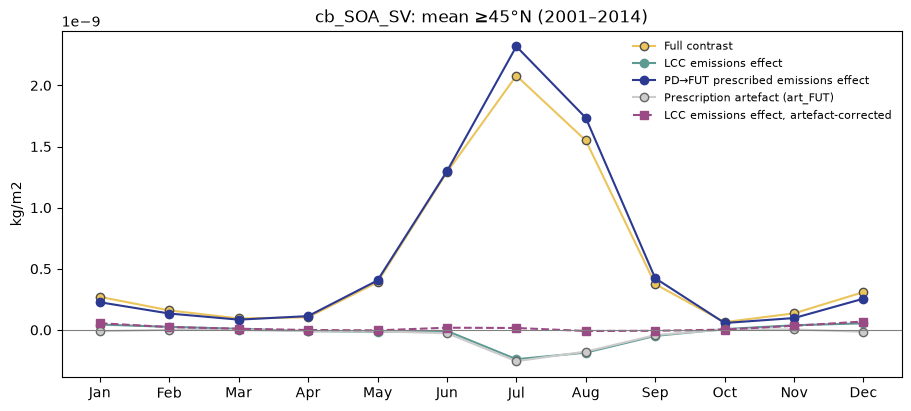

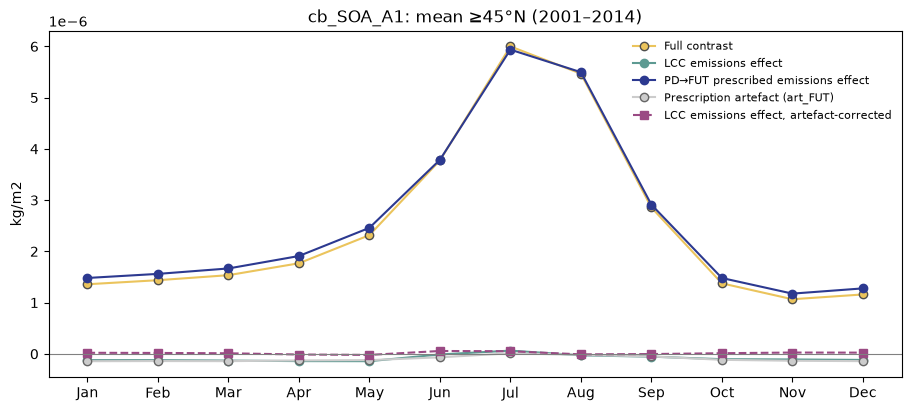

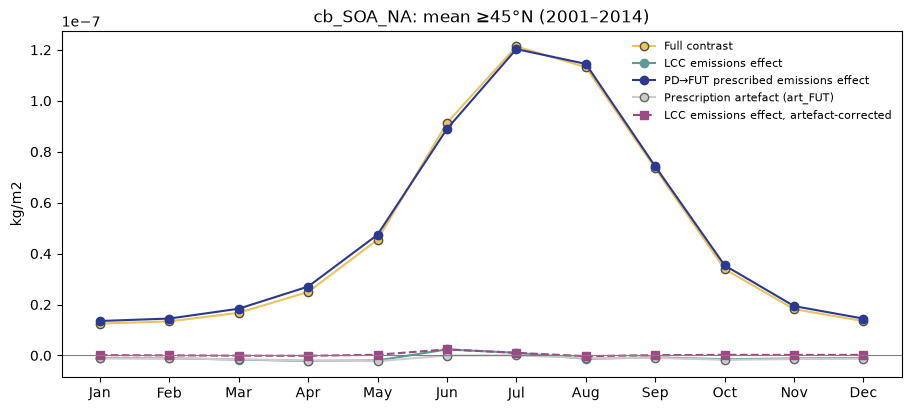

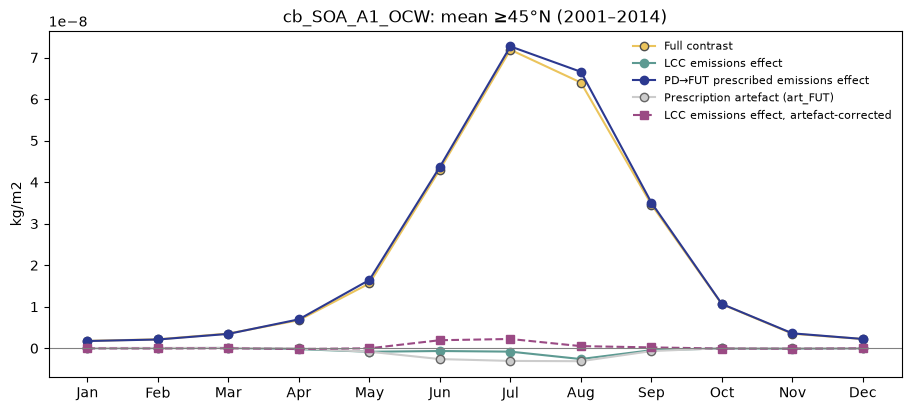

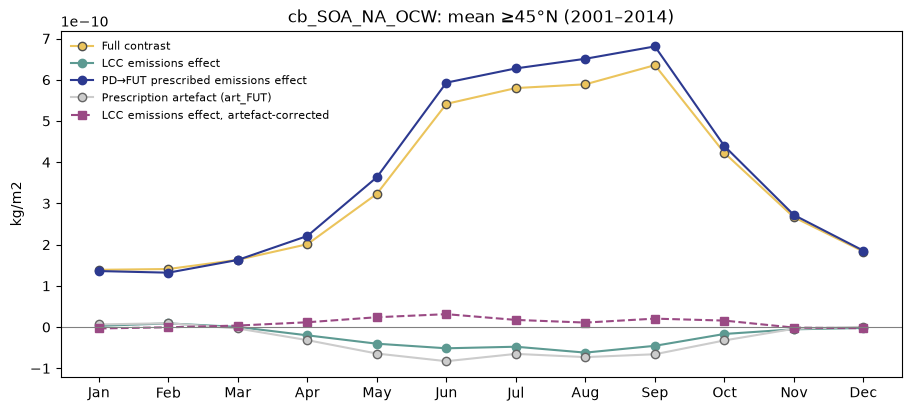

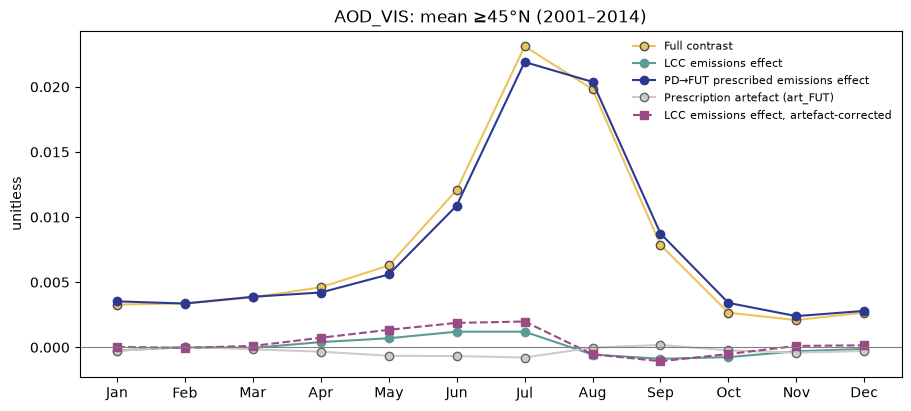

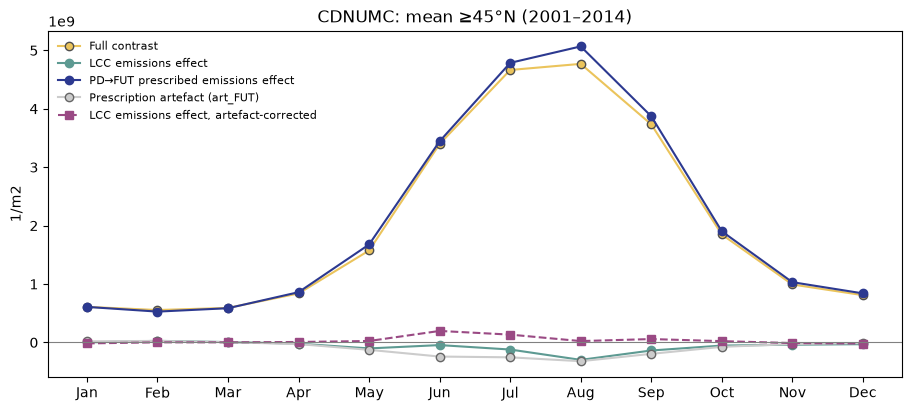

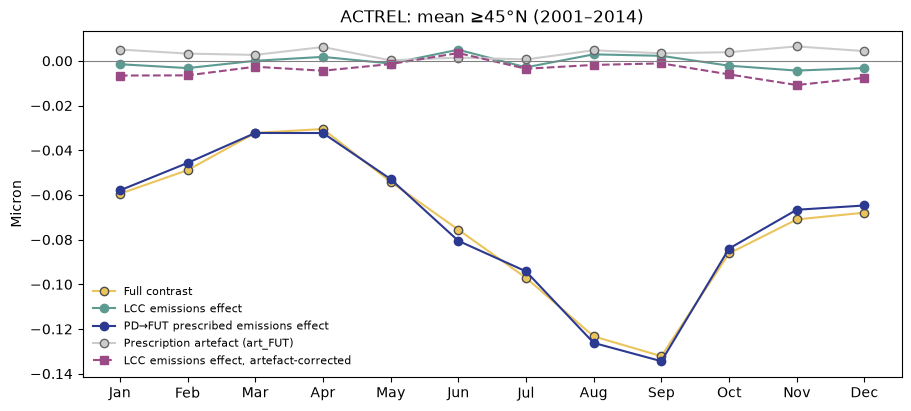

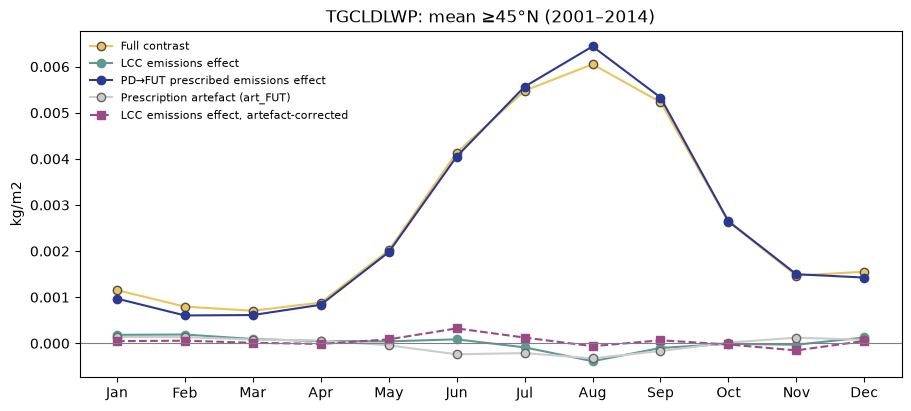

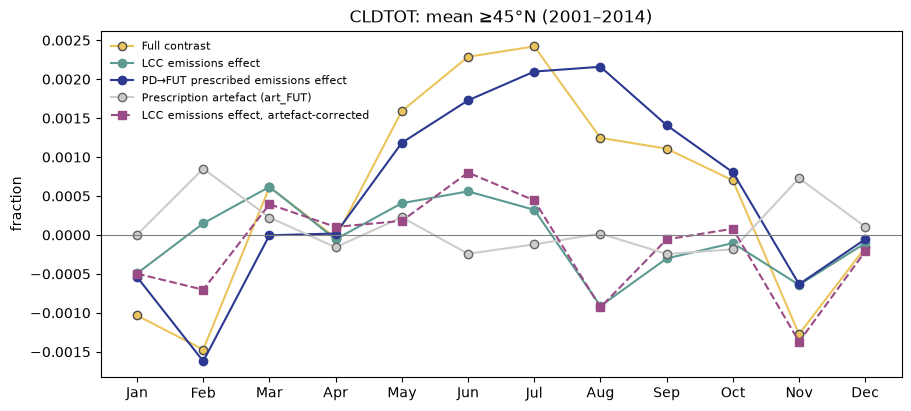

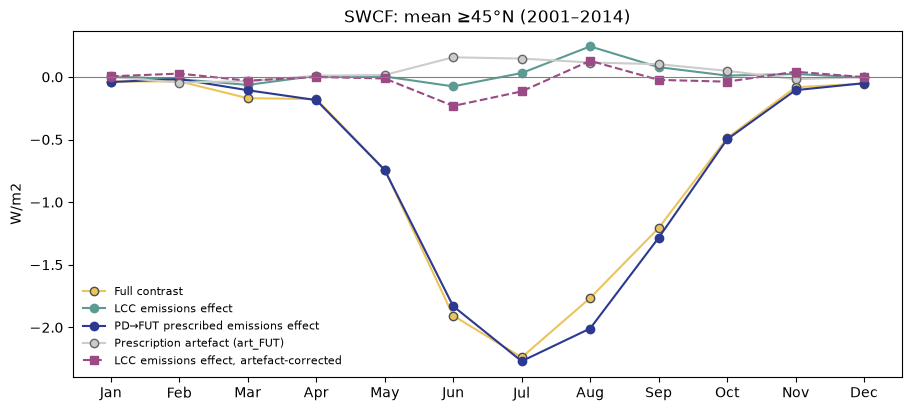

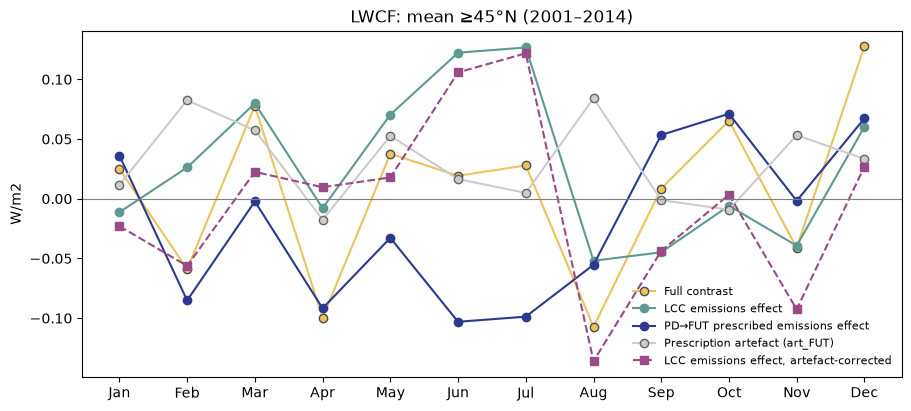

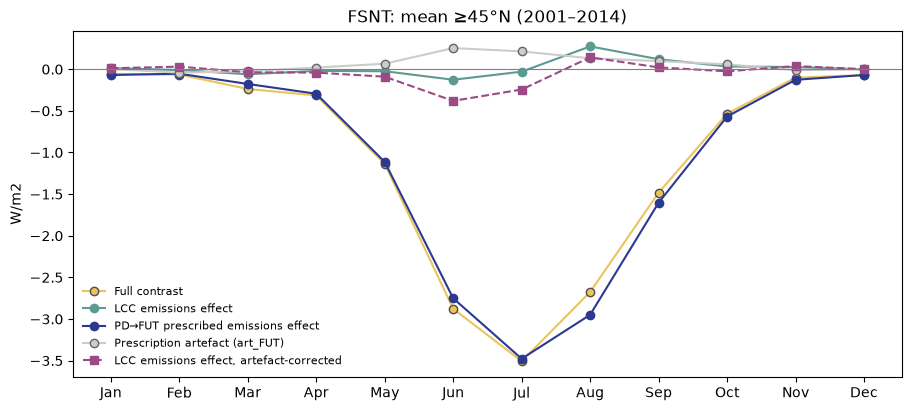

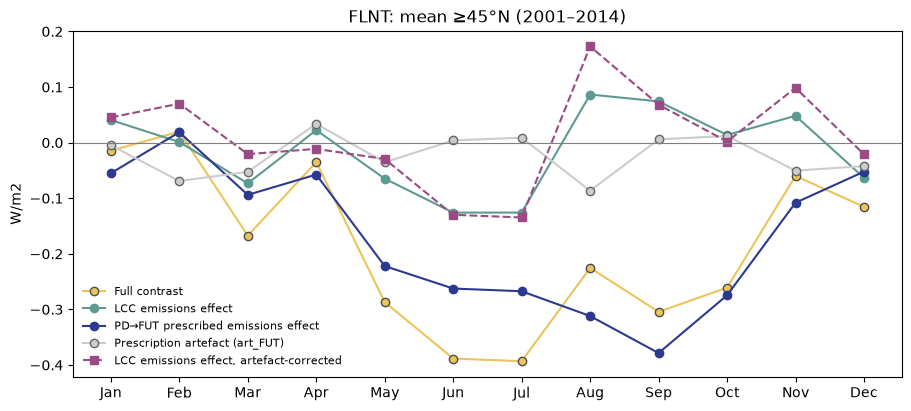

,diagnostic,contrast,mean_change,interannual_SD,p_paired_t,units
0,cb_ISOP,Full contrast,1.649353e-07,1.813999e-08,4.317177e-14,kg/m2
1,cb_ISOP,LCC emissions effect,-4.592953e-09,2.054491e-08,4.180000e-01,kg/m2
2,cb_ISOP,PD→FUT prescribed emissions effect,1.695283e-07,3.446064e-09,1.353535e-23,kg/m2
3,cb_ISOP,Prescription artefact (art_FUT),-1.213367e-08,2.045824e-08,4.488845e-02,kg/m2
4,cb_ISOP,"LCC emissions effect, artefact-corrected",7.540713e-09,2.152243e-09,7.185731e-09,kg/m2
5,cb_MTERP,Full contrast,1.326824e-07,8.214250e-09,2.575575e-17,kg/m2
6,cb_MTERP,LCC emissions effect,-5.309265e-09,8.952359e-09,4.489981e-02,kg/m2
7,cb_MTERP,PD→FUT prescribed emissions effect,1.379917e-07,1.600536e-09,9.214262e-27,kg/m2
8,cb_MTERP,Prescription artefact (art_FUT),-6.556822e-09,9.922156e-09,2.799813e-02,kg/m2
9,cb_MTERP,"LCC emissions effect, artefact-corrected",1.247556e-09,1.408005e-09,5.581241e-03,kg/m2


In [20]:
loaded_atm = {}
for case in ATM_CASES:
    print(f"Loading {case}")
    loaded_atm[case] = load_monthly_dataset(CAM[case], ATM_VARIABLES)

CONTRASTS = {  # name: (minuend, subtrahend)
    "Full contrast": ("LCC_FUT", "LCC_FUT_fBVOCctrlPD"),
    "LCC emissions effect": ("LCC_FUT", "LCC_FUT_fBVOCctrlFUT"),
    "PD→FUT prescribed emissions effect": ("LCC_FUT_fBVOCctrlFUT", "LCC_FUT_fBVOCctrlPD"),
    "Prescription artefact (art_FUT)": ("CTRL_FUT", "CTRL_FUT_fBVOCctrlFUT"),   # interactive − prescribed (user 2026-11-07)
}
STYLE = {"Full contrast": dict(color=GOLD, marker="o", mec="0.3"),
         "LCC emissions effect": dict(color=TEAL, marker="o"),
         "PD→FUT prescribed emissions effect": dict(color=NAVY, marker="o"),
         "Prescription artefact (art_FUT)": dict(color=LIGHT_GREY, marker="o", mec="0.4"),
         "LCC emissions effect, artefact-corrected": dict(color=PLUM, marker="s", ls="--")}

response_rows = []
for label in ATM_VARIABLES:
    units = loaded_atm["LCC_FUT"][label].attrs["units"]
    # float64: the fields are float32, and differences of large fluxes (e.g. FSNT ~300 W m-2) carry ~1e-5 rounding,
    # which failed the identity check below on 3 Nov (2026-11-06 fix)
    responses = {name: paired_difference(loaded_atm[a][label].astype("float64"), loaded_atm[b][label].astype("float64"))
                 for name, (a, b) in CONTRASTS.items()}
    # Identity (A−B)+(B−C) = A−C. Tolerance scaled to the field: CDNUMC is ~1e10, so float64 rounding (~1e-6)
    # exceeds the default atol 1e-8 where the difference crosses zero (failed 6 Nov; 2026-11-07 fix)
    scale = float(np.abs(loaded_atm["LCC_FUT"][label]).max())
    xr.testing.assert_allclose(responses["LCC emissions effect"] +
                               responses["PD→FUT prescribed emissions effect"], responses["Full contrast"],
                               rtol=0, atol=1e-12 * scale)
    responses["LCC emissions effect, artefact-corrected"] = (responses["LCC emissions effect"] -
                                                             responses["Prescription artefact (art_FUT)"])
    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    for name, field in responses.items():
        series = regional_series(field, north)
        cycle = (series * seconds).groupby("month").sum() / seconds.groupby("month").sum()
        ax.plot(cycle.month, cycle, label=name, **STYLE[name])
        yearly = (series * seconds).groupby("year").sum() / seconds.groupby("year").sum()
        response_rows.append({"diagnostic": label, "contrast": name,
                              "mean_change": float((series * seconds).sum() / seconds.sum()),
                              "interannual_SD": float(yearly.std(ddof=1)),
                              "p_paired_t": float(sps.ttest_1samp(yearly.values, 0.0).pvalue),
                              "units": units})
    ax.axhline(0, color="0.5", linewidth=.8)
    ax.set(title=f"{label}: mean ≥{MIN_LAT}°N ({START_YEAR}–{END_YEAR})", ylabel=units,
           xticks=range(1, 13), xticklabels=list(calendar.month_abbr)[1:])
    ax.legend(frameon=False, fontsize=8)
    safe_label = "".join(c if c.isalnum() else "_" for c in label)
    fig.savefig(OUT / f"atmospheric_response_{safe_label}.png", dpi=200)
    plt.show()
response_summary = pd.DataFrame(response_rows)
pd.set_option("display.max_rows", 200)
display(response_summary)
response_summary.to_csv(OUT / "atmospheric_response_decomposition.csv", index=False)

## Findings from sections 14–17 (2001–2014)

Run 7 Nov 2026, new chain, means over ≥45°N. Numbers from `mechanism_JJA_changes.csv`, `PFT_changes_modified_cells.csv`, `fixed_emissions_vs_source.csv` and `atmospheric_response_decomposition.csv`; p = paired t-test of the 14 yearly means (no correction for testing many diagnostics).

**§14 Environmental controls, JJA, LCC_FUT − CTRL_FUT (a).** In the modified cells: TLAI −0.34 m² m⁻², vegetation temperature TV +0.34 K, TREFHT +0.10 K, FSDS +0.24 W m⁻². In the isoprene decrease hotspots the same signs are stronger: TLAI −0.92, TV +0.60 K, FSDS +0.83 W m⁻². Unmodified cells: all ≈ 0. Reading (b): lower LAI in the hotspots would lower canopy emission, and the warmer canopy partly offsets it. This is a coincidence of changes, not an attribution.

**§15 PFT changes in the modified cells (a, grid-area-weighted natural-PFT percentage points):** C3 arctic grass −7.9, bare −3.5; broadleaf deciduous boreal tree +4.8, needleleaf deciduous boreal tree +2.8, needleleaf evergreen boreal tree +2.3, broadleaf deciduous boreal shrub +0.7, broadleaf deciduous temperate tree +0.7.

**§16 Prescribed emissions match their sources (a).** All three fixed runs (LCC_FUT_fBVOCctrlPD ← CTRL_PD, LCC_FUT_fBVOCctrlFUT ← CTRL_FUT, LCC_FUT_fBVOClccPD ← LCC_PD) are within −0.047 % of the source budgets, for both species and every region, with mean-map RMSE ≤ 0.002 mg m⁻² d⁻¹. The same −0.047 % everywhere points to a constant time-weighting offset (b), not a spatial error.

**§17 Atmospheric response, ≥45°N (a):**

| | Full contrast | PD→FUT prescribed emissions | LCC emissions effect | art_FUT | LCC effect, corrected |
|---|---|---|---|---|---|
| FSNT (W m⁻²) | −1.10 (p < 0.001) | −1.11 (p < 0.001) | +0.02 (p 0.72) | +0.06 (p 0.005) | −0.05 (p 0.40) |
| FLNT (W m⁻², upward) | −0.19 (p < 0.001) | −0.17 (p < 0.001) | −0.01 (p 0.72) | −0.02 (p 0.26) | +0.01 (p 0.84) |
| **Net TOA = FSNT − FLNT** (W m⁻²) | **−0.91** | **−0.94** | **+0.03** | **+0.09** | **−0.06** |
| SWCF (W m⁻²) | −0.75 (p < 0.001) | −0.77 (p < 0.001) | +0.02 (p 0.48) | +0.04 (p 0.011) | −0.02 (p 0.50) |
| SOA burden `cb_SOA_A1` (mg m⁻²) | +2.52 | +2.61 (p < 0.001) | −0.085 (p < 0.001) | −0.099 (p < 0.001) | +0.014 (p 0.10) |
| CDNUMC (10⁸ m⁻²) | +20.4 | +21.1 (p < 0.001) | −0.69 (p 0.03) | −1.04 (p 0.002) | +0.35 (p 0.002) |
| AOD_VIS | +0.0077 | +0.0076 (p < 0.001) | +0.0000 (p 0.92) | −0.0003 (p 0.13) | +0.0004 (p 0.55) |

1. **Against CTRL_PD emissions, almost all of the response is the PD→FUT emission change (a).** Net TOA −0.94 of −0.91 W m⁻², mostly shortwave cloud (SWCF −0.77). It comes with +2.6 mg m⁻² SOA and +2.1 × 10⁹ m⁻² cloud droplets. So the Full contrast (LCC_FUT − LCC_FUT_fBVOCctrlPD) measures the climate-driven emission increase, not forest expansion.
2. **The forest-expansion emission effect on radiation is not distinguishable from zero (a).** Corrected net TOA −0.06 W m⁻², FSNT p = 0.40, SWCF p = 0.50.
3. **The artefact is as large as the LCC effect and has the same sign (a)** (art = interactive − prescribed, user 2026-11-07; signs of the art_FUT column converted from the 7 Nov run, which used the opposite sign). For SOA (−0.099 vs −0.085 mg m⁻²) and CDNUMC (−1.04 vs −0.69 × 10⁸ m⁻²), subtracting art_FUT turns a significant decrease into a small increase. The uncorrected LCC effect must not be reported for these fields. The correction assumes art(LCC land) ≈ art(CTRL land), which was tested in PD only (b for FUT).
4. **Microphysics responds, radiation does not, after correction (a/b).** CDNUMC +0.35 × 10⁸ m⁻² (p 0.002, ~1.7 % of the PD→FUT change) with no detectable SWCF change. The droplet signal is real at this sample size; its radiative effect is below the interannual noise (SD of corrected FSNT 0.21 W m⁻²).

Caveats: regional means over ≥45°N only (no Ghan split here; see `analysis/fut-fbvoc-emission-source-choice.ipynb`); the prescribed climatology has no interannual or weather coupling; p values are descriptive.


## Recommended reading order
1. Regional totals: locate the negative expansion contribution.
2. Seasonal and cancellation panels: identify active months and opposing spatial changes.
3. Ranked cells and narrow-scale maps: identify the locations to investigate.
4. PFT and environmental diagnostics: evaluate candidate mechanisms without treating correlation as proof.
5. Fixed-emission checks: verify the intended reference contrasts.
6. Atmospheric comparisons: diagnose the aerosol/cloud/radiative responses independently of the sign of the emissions total.

All outputs go to `bvoc_emissions_decomposition-after-co2-fix_outputs/`. This notebook is standalone.